# xBD — EDA, Data Cleaning & Pretrained Change-Detection Model

**Author:** Artur Zavistovskyi · **Team part:** pretrained model + EDA + data cleaning
**Project:** Mapping Natural-Disaster Damage from Satellite Imagery
**This copy:** local run — reads `make_splits.py` output directly from disk, no Kaggle account needed
**Reference run:** Kaggle T4 · full xBD (11,034 scenes) · build r5

---

# Results

*The numbers below are the reference run (Kaggle T4, `SCENE_BUDGET` at its default). Running
this notebook locally on the same `splits.csv` with the same seed should reproduce them to
within sampling noise. Change `SCENE_BUDGET` and they will move — that is expected, not a bug.*

Per-building damage classification from co-registered pre/post satellite patches, trained on
**non-fire** disasters and tested on **wildfire**, a disaster type the model never saw.

| | accuracy | macro-F1 | macro ROC-AUC |
|---|---|---|---|
| `val` — seen types, used for selection | 0.793 | 0.640 | 0.916 |
| `test_id` — seen types, never tuned on | **0.775** | **0.637** | 0.917 |
| `test_ood` — **wildfire, never seen** | **0.636** | **0.396** | 0.797 |
| cross-disaster drop | −13.9 pp (−17.9%) | −24.1 pp (−37.9%) | −0.12 |

`val` and `test_id` agree to within 0.004 macro-F1, so the in-distribution number is stable and the
gap below is a real domain effect, not noise.

### The headline finding: the model transfers, its calibration does not

Macro-F1 falls by 38% out of domain, but the per-class breakdown shows that number is misleading:

| class | F1 `test_id` | F1 `test_ood` | precision `test_ood` | true count in `test_ood` |
|---|---|---|---|---|
| no-damage | 0.877 | 0.765 | 0.977 | 12,056 |
| minor-damage | 0.502 | **0.023** | **0.012** | 116 |
| major-damage | 0.539 | **0.042** | **0.022** | 138 |
| destroyed | 0.631 | **0.754** | 0.801 | 2,317 |

**`destroyed` scores *higher* on wildfire than in-domain** (0.754 vs 0.631), and `no-damage`
precision is 0.977. The two classes that actually occur in wildfire are recognised well by a model
that has never seen a fire. The collapse is entirely in `minor` and `major`, and it is a base-rate
effect: those classes are 10.5% and 8.6% of training patches but only **0.79%** and **0.94%** of
wildfire patches. A classifier calibrated for a 10% prior fires ~4,800 minor/major predictions
against 254 true cases, so precision is capped near 0.02 no matter how good the features are.

Three independent signals point the same way:

1. **85.6% of out-of-domain errors over-estimate severity**, only 14.4% under-estimate — a
   systematic direction, which is the signature of a prior shift rather than diffuse feature failure.
2. **ROC-AUC, which is threshold-free, holds at 0.797** out of domain versus 0.917 in domain. The
   ranking survives; only the decision boundary is wrong.
3. The EDA prediction made *before* training — that undamaged buildings in burnt surroundings would
   be over-flagged — came out at **37.2% false alarms** on true `no-damage` wildfire buildings.

**Operational reading.** Deployed on a new disaster type with no labels, this model would reliably
separate destroyed from intact, and would badly over-report intermediate damage. That is a
recalibration problem — far more tractable than a representation problem.

### Data findings that shaped the pipeline

- **Wildfire damage is bimodal.** Averaged over events: non-fire is 70.2 / 9.9 / 7.2 / 6.5 %
  across the four classes, wildfire is 78.8 / **1.2** / **1.1** / **14.8** %. Fire leaves buildings
  intact or destroys them; intermediate states barely exist.
- **54.1% of wildfire scenes contain no buildings at all** (median 0 per scene), against 9.8% in
  train — which is why scenes are sampled subject to a minimum building count.
- **No occlusion label exists in xBD.** The diagnostic in 4.3 found the worst-occluded tiles are
  **cloud over `sunda-tsunami` and `lower-puna-volcano`, not smoke over wildfire** — 14 flagged
  scenes, all in train/val, none in either test set. Nothing was removed.
- **Cleaning cost 6.7% of polygons** (3.29% un-classified, 3.51% footprints under 8 px), at a
  removal rate that is uniform across splits (2.99–3.77%), so it cannot tilt the comparison.

### Scale

135,262 patch pairs from 1,698 scenes — 72,916 train / 20,446 val / 27,273 test_id / 14,627 test_ood.
Extraction 2.3 min, training 14 epochs in ~5.5 min on a T4.

---

## What this notebook does

`splits.csv → label scan → EDA → cleaning/diagnostics → patch extraction → siamese ResNet18 → evaluation`

Two 64×64 patches of the **same building**, cropped from the same pixel box in the pre- and
post-disaster tile, predict one of four damage levels.

| split | what it measures |
|---|---|
| `train` / `val` | tier1+tier3, non-fire — fitting and model selection |
| `test_id` | official test+hold, non-fire — in-distribution reference |
| `test_ood` | every wildfire scene — zero-shot, the headline result |

## Running this locally

Put this notebook in the project root — the directory `make_splits.py` was run from, holding:

```
splits.csv
splits_summary.csv
xbd/
   hold/  test/  tier1/  tier3/       each with images/ labels/ masks/
```

Paths resolve themselves from there. If the notebook lives elsewhere, set `PROJECT_ROOT_OVERRIDE`
in the PATHS cell to an absolute path — nothing else needs touching.

```
pip install torch torchvision numpy pandas matplotlib pillow scikit-learn pyarrow notebook
```

For a CUDA build of torch use the selector at <https://pytorch.org/get-started/locally/>. A CPU-only
install works end to end; see the device cell for how to shrink the budget if it is too slow.

**Internet is needed once**, to fetch the ImageNet ResNet18 weights (45 MB). Torchvision caches them
in `~/.cache/torch/`, so later runs are offline.

**Outputs** go to `work/` next to the notebook: `cache/` (parquet scans, so a re-run skips the slow
steps), `patches/` (~3.5 GB of extracted arrays), `checkpoints/`, and the result CSVs. It is all
derived data — gitignore it.

## Two deliberate design choices

- **Paths come only from `splits.csv`**, never from a directory scan. Some xBD mirrors ship an
  extra `xbd/train/` duplicate of `tier1`; globbing would place the same scene in two splits.
- **Nothing is deleted silently.** Every cleaning rule states its threshold, its cost, and its
  per-split removal rate; anything that cannot be justified is flagged for review instead.

## 1 · Setup

In [1]:
# ---------------------------------------------------------------- dependency check
# Kaggle ships all of these preinstalled; a fresh local environment usually does not.
# Fail here with an actionable message rather than with an ImportError halfway down.
import importlib.util

REQUIRED = {
    "numpy": "numpy", "pandas": "pandas", "matplotlib": "matplotlib", "PIL": "pillow",
    "torch": "torch", "torchvision": "torchvision", "sklearn": "scikit-learn",
    "pyarrow": "pyarrow",          # pandas needs this for the .parquet caches
}

missing = [pkg for mod, pkg in REQUIRED.items() if importlib.util.find_spec(mod) is None]
if missing:
    raise ImportError(
        "Missing packages: " + ", ".join(missing) + "\n\n"
        "    pip install " + " ".join(missing) + "\n\n"
        "For a CUDA build of torch use the selector at https://pytorch.org/get-started/locally/\n"
        "(the CPU build works too - see the device cell for how to shrink the budget).")

print("all required packages present")

all required packages present


In [2]:
# ---------------------------------------------------------------- imports
import os, sys, json, re, time, math, warnings
from pathlib import Path
from concurrent.futures import ThreadPoolExecutor

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageFile

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

warnings.filterwarnings("ignore", category=UserWarning)
ImageFile.LOAD_TRUNCATED_IMAGES = False   # we WANT truncated files to raise, so we can count them
Image.MAX_IMAGE_PIXELS = None

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25,
                     "axes.spines.top": False, "axes.spines.right": False})

BUILD = "r5 (2026-08-20) — threaded extraction + I/O probe + skippable galleries"
print("notebook build:", BUILD)
print("python     ", sys.version.split()[0])
print("numpy      ", np.__version__)
print("pandas     ", pd.__version__)
print("torch      ", torch.__version__)

notebook build: r5 (2026-08-20) — threaded extraction + I/O probe + skippable galleries
python      3.13.7
numpy       2.4.4
pandas      2.3.3
torch       2.12.0.dev20260408+cu128


In [3]:
# ---------------------------------------------------------------- device
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
if DEVICE == "cuda":
    print("GPU        ", torch.cuda.get_device_name(0))
    print("VRAM       ", f"{torch.cuda.get_device_properties(0).total_memory / 1e9:.1f} GB")
else:
    print("Device     : CPU (no CUDA available)")
    print("             The notebook runs end to end on CPU, but training is far slower.")
    print("             If that is impractical, shrink SCENE_BUDGET in the config cell to")
    print("             about {'train': 250, 'val': 80, 'test_id': 120, 'test_ood': 150}.")
    print("             Every step and conclusion stays identical - the metrics just get noisier.")

# ---------------------------------------------------------------- reproducibility
SEED = 42            # same seed as make_splits.py, so anything re-derived here matches the team split

def set_seed(seed=SEED):
    import random
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)

set_seed()
print("seed       ", SEED)

GPU         NVIDIA GeForce RTX 5060 Laptop GPU
VRAM        8.5 GB
seed        42


In [4]:
# ================================================================ CONFIGURATION
# Everything tunable lives here. Nothing below this cell hard-codes a magic number.

# --- labels: the xBD 4-level joint damage scale -------------------------------
DAMAGE_CLASSES = ["no-damage", "minor-damage", "major-damage", "destroyed"]
NAME_TO_IDX    = {n: i for i, n in enumerate(DAMAGE_CLASSES)}
NUM_CLASSES    = len(DAMAGE_CLASSES)
SHORT          = ["none", "minor", "major", "destr"]      # compact axis labels

# "un-classified" is a 5th value annotators used when a building could NOT be assessed.
# It is not a damage level, so it is excluded from training - but it is our single best
# occlusion signal, so we keep and analyse it in section 4.3.
UNCLASSIFIED   = "un-classified"

# --- the four xBD source directories (xbd/train/ is EXCLUDED, see 1.4) --------
ORIGINS = ("hold", "test", "tier1", "tier3")
SPLITS  = ("train", "val", "test_id", "test_ood")

# --- patch extraction ---------------------------------------------------------
PATCH_SIZE   = 64     # px. Justified against the measured bbox distribution in section 3.4.
BBOX_PAD     = 10     # px of context kept around each building footprint
MIN_BBOX_PX  = 8      # cleaning rule: drop footprints smaller than this (section 4.5)
MIN_BUILDINGS_PER_SCENE = 5    # scene-sampling filter, calibrated in section 5.2

# Scene budget per split. Kaggle gives 9h of GPU and 20 GB of /kaggle/working, so we extract
# patches from a stratified SAMPLE of scenes rather than all 11,034. Raise for the final run.
SCENE_BUDGET = {"train": 800, "val": 200, "test_id": 300, "test_ood": 400}

# --- diagnostics --------------------------------------------------------------
QC_SAMPLE_SCENES = 400    # scenes used for pixel-level image QC and duplicate hashing
OCCLUSION_TOP_N  = 12     # occlusion candidates displayed for manual review
SHOW_EXAMPLE_GRIDS = True # section 3.7 galleries; set False if the mount is slow (cosmetic only)

# --- I/O ----------------------------------------------------------------------
# On a local SSD reads are far quicker than on Kaggle's network mount, but decoding
# 1024x1024 PNGs still dominates. PIL releases the GIL while decoding, so threads help.
# On a spinning disk, lower both: concurrent random reads make seek time worse.
IO_WORKERS      = 16   # threads for the diagnostic scans
EXTRACT_WORKERS = 8    # threads for patch extraction (each holds two 1024x1024 tiles)

# --- training -----------------------------------------------------------------
BATCH_SIZE   = 128
EPOCHS_HEAD  = 4      # phase 1: frozen backbone, train the head only
EPOCHS_FT    = 10     # phase 2: unfreeze layer3 + layer4 and fine-tune
LR_HEAD      = 1e-3
LR_FT        = 1e-4
WEIGHT_DECAY = 1e-4
PATIENCE     = 3      # early stopping on val macro-F1
NUM_WORKERS  = 0      # 0 on purpose: DataLoader workers use spawn on Windows and hang in
                      # Jupyter. The patches are a memmap of 64x64 tiles, so loading is
                      # not the bottleneck anyway. Raise to 4 on Linux/macOS if you like.

IMAGENET_MEAN = np.array([0.485, 0.456, 0.406], np.float32)
IMAGENET_STD  = np.array([0.229, 0.224, 0.225], np.float32)

print("patch", PATCH_SIZE, "| scene budget", SCENE_BUDGET,
      "| budgeted scenes", sum(SCENE_BUDGET.values()))

patch 64 | scene budget {'train': 800, 'val': 200, 'test_id': 300, 'test_ood': 400} | budgeted scenes 1700


In [5]:
# ================================================================ PATHS (local run)
# This is the layout make_splits.py already produces - nothing has to be re-arranged:
#
#   <project root>/
#       splits.csv                 <- written by make_splits.py
#       splits_summary.csv
#       xbd/{hold,test,tier1,tier3}/{images,labels,masks}/
#
# splits.csv stores every path relative to the project root (xbd/test/labels/x.json, with
# Windows separators), so resolving that one directory resolves all 77,238 rows. Drop this
# notebook in the project root and nothing below needs editing.

PROJECT_ROOT_OVERRIDE = None    # e.g. r"D:\projects\satellite-disaster-damage-mapping"
OUTPUT_DIR_OVERRIDE   = None    # defaults to <project root>/work


def find_project_root():
    """Look for splits.csv sitting next to xbd/ - in the override, then cwd, then its parents."""
    cands = [Path(PROJECT_ROOT_OVERRIDE)] if PROJECT_ROOT_OVERRIDE else []
    here = Path.cwd().resolve()
    cands += [here, *here.parents]

    for d in cands:                    # ideal: splits.csv and xbd/ in the same directory
        if (d / "splits.csv").is_file() and (d / "xbd" / "tier1" / "images").is_dir():
            return d
    for d in cands:                    # acceptable: xbd/ found, splits.csv resolved separately
        if (d / "xbd" / "tier1" / "images").is_dir():
            return d
    return None


PROJECT_ROOT = find_project_root()
print("cwd          :", Path.cwd())
print("project root :", PROJECT_ROOT)

if PROJECT_ROOT is None:
    raise FileNotFoundError(
        "Dataset not found.\n"
        "Expected a directory containing BOTH splits.csv and xbd/tier1/images/ .\n"
        "Either move this notebook into that directory, or set PROJECT_ROOT_OVERRIDE above.\n"
        f"Searched upwards from: {Path.cwd()}")

WORK   = Path(OUTPUT_DIR_OVERRIDE) if OUTPUT_DIR_OVERRIDE else PROJECT_ROOT / "work"
CACHE  = WORK / "cache";       CACHE.mkdir(parents=True, exist_ok=True)
ARRAYS = WORK / "patches";     ARRAYS.mkdir(parents=True, exist_ok=True)
CKPT   = WORK / "checkpoints"; CKPT.mkdir(parents=True, exist_ok=True)

print("outputs      :", WORK)
print("\nNote: `work/` will hold ~3.5 GB of extracted patches at the default SCENE_BUDGET.")
print("It is derived data - add it to .gitignore, do not commit it.")

cwd          : c:\Users\bhvns\Documents\University of Konstanz\Courses\satellite-disaster-damage-mapping
project root : C:\Users\bhvns\Documents\University of Konstanz\Courses\satellite-disaster-damage-mapping
outputs      : C:\Users\bhvns\Documents\University of Konstanz\Courses\satellite-disaster-damage-mapping\work

Note: `work/` will hold ~3.5 GB of extracted patches at the default SCENE_BUDGET.
It is derived data - add it to .gitignore, do not commit it.


In [6]:
# ---------------------------------------------------------------- resolve the dataset
# Everything downstream is written against XBD_BASE + STRIP_XBD_PREFIX, so the local run only
# has to fill those two in. splits.csv paths already begin with "xbd/", and PROJECT_ROOT is the
# directory that contains xbd/, so nothing is stripped.
XBD_BASE         = PROJECT_ROOT
STRIP_XBD_PREFIX = False
XBD              = PROJECT_ROOT / "xbd"
SPLITS_CSV       = PROJECT_ROOT / "splits.csv"

if not SPLITS_CSV.is_file():
    raise FileNotFoundError(
        f"splits.csv not found at {SPLITS_CSV}\n"
        "Regenerate it from the project root with:\n"
        "    python make_splits.py --src xbd --out .")

print("xbd        :", XBD)
print("splits.csv :", SPLITS_CSV, f"({SPLITS_CSV.stat().st_size / 1e6:.1f} MB)")

xbd        : C:\Users\bhvns\Documents\University of Konstanz\Courses\satellite-disaster-damage-mapping\xbd
splits.csv : C:\Users\bhvns\Documents\University of Konstanz\Courses\satellite-disaster-damage-mapping\splits.csv (13.9 MB)


In [7]:
# ---------------------------------------------------------------- what is actually on disk
print("directories under", XBD, ":")
for d in sorted(p for p in XBD.iterdir() if p.is_dir()):
    subs = sorted(s.name for s in d.iterdir() if s.is_dir())
    tag  = "   <- USED" if d.name in ORIGINS else "   <- IGNORED (absent from splits.csv)"
    print(f"  {d.name:8s} {subs}{tag}")

missing = [o for o in ORIGINS if not (XBD / o / "images").is_dir()]
if missing:
    raise FileNotFoundError(f"missing required origin directories: {missing}")

print("\nWhy xbd/train/ is ignored: in xBD the official train set IS tier1 (2,799 scenes).")
print("This mirror ships a duplicate copy under xbd/train/. It is absent from splits.csv;")
print("including it would place the same scene in two splits and corrupt the experiment.")

directories under C:\Users\bhvns\Documents\University of Konstanz\Courses\satellite-disaster-damage-mapping\xbd :
  hold     ['images', 'labels', 'masks']   <- USED
  test     ['images', 'labels', 'masks']   <- USED
  tier1    ['images', 'labels', 'masks']   <- USED
  tier3    ['images', 'labels', 'masks']   <- USED

Why xbd/train/ is ignored: in xBD the official train set IS tier1 (2,799 scenes).
This mirror ships a duplicate copy under xbd/train/. It is absent from splits.csv;
including it would place the same scene in two splits and corrupt the experiment.


## 2 · Dataset inspection

### 2.1 Load the team split

`splits.csv` is the output of `make_splits.py` (Bhuvanesh). One row per file, 7 files per scene:
`images/{pre,post}`, `labels/{pre,post}`, `masks/{pre,post,post_rgb}`.

We keep only `images` and `labels` — the `masks/` folder holds **segmentation** targets, which this
per-building **classification** task does not use.

In [8]:
splits_raw = pd.read_csv(SPLITS_CSV)
print("splits.csv:", splits_raw.shape)
display(splits_raw.head(3))

print("\nfiles per subdir / kind:")
display(splits_raw.groupby(["subdir", "kind"]).size().rename("files").reset_index())


def to_abs(rel_path: str) -> str:
    """Rewrite a Windows-relative path from splits.csv into a Kaggle absolute path."""
    rel = str(rel_path).replace("\\", "/")
    if STRIP_XBD_PREFIX and rel.startswith("xbd/"):
        rel = rel[len("xbd/"):]
    return str(XBD_BASE / rel)


# Keep images + labels, drop masks, then pivot to ONE ROW PER SCENE with the 4 resolved paths.
keep = splits_raw[splits_raw.subdir.isin(["images", "labels"])].copy()
keep["abs_path"] = keep["path"].map(to_abs)
keep["col"] = keep.subdir.map({"images": "img", "labels": "lab"}) + "_" + keep.kind

scenes = (keep.pivot_table(index=["scene_id", "disaster", "origin", "split"],
                           columns="col", values="abs_path", aggfunc="first")
              .reset_index())
scenes.columns.name = None
scenes = scenes.rename(columns={"img_pre_disaster": "img_pre", "img_post_disaster": "img_post",
                                "lab_pre_disaster": "lab_pre", "lab_post_disaster": "lab_post"})
scenes["is_fire"] = scenes.split.eq("test_ood")

print(f"\n{len(scenes)} scenes | {scenes.disaster.nunique()} disaster events")
display(scenes.head(3))

splits.csv: (77238, 8)


,name,path,subdir,scene_id,disaster,kind,origin,split
0,guatemala-volcano_00000003_post_disaster.json,xbd\test\labels\guatemala-volcano_00000003_pos...,labels,guatemala-volcano_00000003,guatemala-volcano,post_disaster,test,test_id
1,guatemala-volcano_00000003_post_disaster.png,xbd\test\images\guatemala-volcano_00000003_pos...,images,guatemala-volcano_00000003,guatemala-volcano,post_disaster,test,test_id
2,guatemala-volcano_00000003_post_disaster.png,xbd\test\masks\guatemala-volcano_00000003_post...,masks,guatemala-volcano_00000003,guatemala-volcano,post_disaster,test,test_id



files per subdir / kind:


,subdir,kind,files
0,images,post_disaster,11034
1,images,pre_disaster,11034
2,labels,post_disaster,11034
3,labels,pre_disaster,11034
4,masks,post_disaster,11034
5,masks,post_disaster_rgb,11034
6,masks,pre_disaster,11034



11034 scenes | 19 disaster events


,scene_id,disaster,origin,split,img_post,img_pre,lab_post,lab_pre,is_fire
0,guatemala-volcano_00000000,guatemala-volcano,tier1,train,C:\Users\bhvns\Documents\University of Konstan...,C:\Users\bhvns\Documents\University of Konstan...,C:\Users\bhvns\Documents\University of Konstan...,C:\Users\bhvns\Documents\University of Konstan...,False
1,guatemala-volcano_00000001,guatemala-volcano,tier1,train,C:\Users\bhvns\Documents\University of Konstan...,C:\Users\bhvns\Documents\University of Konstan...,C:\Users\bhvns\Documents\University of Konstan...,C:\Users\bhvns\Documents\University of Konstan...,False
2,guatemala-volcano_00000002,guatemala-volcano,tier1,train,C:\Users\bhvns\Documents\University of Konstan...,C:\Users\bhvns\Documents\University of Konstan...,C:\Users\bhvns\Documents\University of Konstan...,C:\Users\bhvns\Documents\University of Konstan...,False


In [9]:
# ---------------------------------------------------------------- split integrity, re-verified
# make_splits.py already asserts these. The split is the one thing that can silently invalidate
# every downstream number, so re-checking it after the path rewrite costs nothing.
assert scenes.scene_id.is_unique, "scene_id must be unique after the pivot"
assert scenes[["img_pre", "img_post", "lab_post"]].notna().all().all(), "missing file paths"

print("scenes per split:")
display(scenes.split.value_counts().reindex(SPLITS).rename("scenes").to_frame())

print("\nscenes: disaster x split")
display(pd.crosstab(scenes.disaster, scenes.split).reindex(columns=SPLITS, fill_value=0))

fire_events = sorted(scenes.loc[scenes.is_fire, "disaster"].unique())
leak = scenes[scenes.split.isin(["train", "val"]) & scenes.disaster.isin(fire_events)]
print(f"\nheld-out fire events            : {fire_events}")
print(f"fire scenes in train/val (must be 0): {len(leak)}")
assert len(leak) == 0, "wildfire leaked into the training pool"

scenes per split:


,scenes
split,
train,3135
val,392
test_id,1135
test_ood,6372



scenes: disaster x split


split,train,val,test_id,test_ood
disaster,,,,
guatemala-volcano,16,2,10,0
hurricane-florence,283,36,227,0
hurricane-harvey,283,36,203,0
hurricane-matthew,212,26,167,0
hurricane-michael,305,38,207,0
joplin-tornado,132,17,0,0
lower-puna-volcano,259,32,0,0
mexico-earthquake,108,13,72,0
midwest-flooding,248,31,166,0



held-out fire events            : ['pinery-bushfire', 'portugal-wildfire', 'santa-rosa-wildfire', 'socal-fire', 'woolsey-fire']
fire scenes in train/val (must be 0): 0


**What we see.** 11,034 scenes across 19 events. Five wildfire events (6,372 scenes) sit entirely
in `test_ood`; `train`+`val` hold 3,527 non-fire scenes. No wildfire leaked into training.

**Why it matters.** `test_ood` is larger than the whole training pool, so any dataset-wide statistic
is dominated by wildfire. Every distribution below is therefore reported **per split**.

**Downstream.** Scene sampling is stratified by event, and class weights and thresholds are computed
on `train` only.

### 2.2 Read the labels

Damage labels live in the **post-disaster JSON**, not in `splits.csv`. Structure per file:

```
features.xy[]      -> {"properties": {"subtype": ..., "uid": ...}, "wkt": "POLYGON ((x y, ...))"}
features.lng_lat[] -> the same polygons in WGS84
metadata           -> capture geometry: gsd, off_nadir_angle, sun_elevation, capture_date, ...
```

Two things worth flagging for the team:

- Pre-disaster JSONs carry footprints with **no** `subtype` — they are localisation only.
- `features.lng_lat` gives real lat/lon per building, so **Part 3 does not need the
  `xview_geotransforms` file** that the README lists.

We print the real keys of one file rather than assuming them.

In [10]:
probe = json.loads(Path(scenes.lab_post.iloc[0]).read_text())
print("top-level keys :", list(probe.keys()))
print("features keys  :", list(probe["features"].keys()))
print("metadata keys  :", list(probe["metadata"].keys()))
print("\none xy feature :")
print(json.dumps(probe["features"]["xy"][0], indent=2)[:600])

top-level keys : ['features', 'metadata']
features keys  : ['lng_lat', 'xy']
metadata keys  : ['sensor', 'provider_asset_type', 'gsd', 'capture_date', 'off_nadir_angle', 'pan_resolution', 'sun_azimuth', 'sun_elevation', 'target_azimuth', 'disaster', 'disaster_type', 'catalog_id', 'original_width', 'original_height', 'width', 'height', 'id', 'img_name']

one xy feature :
{
  "properties": {
    "feature_type": "building",
    "subtype": "no-damage",
    "uid": "486b0813-ecd2-4b84-856c-9c0e42156953"
  },
  "wkt": "POLYGON ((532.1863714054954 165.9824503000504, 548.6019827848852 224.1613082732768, 446.2458177229872 264.4761185678668, 440.6934785817455 249.7503495372735, 425.9677095499687 253.1300342329752, 420.8981825090282 232.3691139606, 437.5551999358392 227.0581808684396, 431.2786426428399 201.2277335525121, 532.1863714054954 165.9824503000504))"
}


In [11]:
_WKT_NUM = re.compile(r"-?\d+\.?\d*")


def wkt_bbox(wkt: str):
    """Axis-aligned pixel bbox of a WKT polygon. Numbers alternate x, y."""
    nums = [float(v) for v in _WKT_NUM.findall(wkt)]
    xs, ys = nums[0::2], nums[1::2]
    return min(xs), min(ys), max(xs), max(ys)


def read_post_label(row):
    """Parse one post-disaster JSON -> (per-building records, per-scene metadata record)."""
    try:
        d = json.loads(Path(row.lab_post).read_text())
    except Exception as e:                    # counted as a corrupted label in section 4.2
        return [], {"scene_id": row.scene_id, "label_error": type(e).__name__,
                    "n_buildings": 0, "n_unclassified": 0}

    meta, feats = d.get("metadata", {}), d["features"].get("xy", [])
    recs, n_unc = [], 0
    for f in feats:
        props = f.get("properties", {})
        sub = props.get("subtype", UNCLASSIFIED)
        n_unc += (sub == UNCLASSIFIED)
        minx, miny, maxx, maxy = wkt_bbox(f["wkt"])
        recs.append((row.scene_id, props.get("uid", ""), sub, minx, miny, maxx, maxy))

    scene_rec = {
        "scene_id": row.scene_id, "label_error": None,
        "n_buildings": len(feats), "n_unclassified": n_unc,
        "gsd": meta.get("gsd"), "off_nadir_angle": meta.get("off_nadir_angle"),
        "sun_elevation": meta.get("sun_elevation"), "capture_date": meta.get("capture_date"),
        "disaster_type": meta.get("disaster_type"),
        "img_width": meta.get("width"), "img_height": meta.get("height"),
    }
    return recs, scene_rec

In [12]:
# ---------------------------------------------------------------- full label scan (cached)
BLD_CACHE, SCN_CACHE = CACHE / "buildings.parquet", CACHE / "scene_meta.parquet"

if BLD_CACHE.exists() and SCN_CACHE.exists():
    buildings  = pd.read_parquet(BLD_CACHE)
    scene_meta = pd.read_parquet(SCN_CACHE)
    print("loaded label scan from cache")
else:
    t0 = time.time()
    rows = list(scenes.itertuples(index=False))
    with ThreadPoolExecutor(max_workers=IO_WORKERS) as ex:          # I/O bound: 11k small JSON reads
        out = list(ex.map(read_post_label, rows))
    buildings = pd.DataFrame([r for recs, _ in out for r in recs],
                             columns=["scene_id", "uid", "subtype",
                                      "minx", "miny", "maxx", "maxy"])
    scene_meta = pd.DataFrame([s for _, s in out])
    buildings.to_parquet(BLD_CACHE, index=False)
    scene_meta.to_parquet(SCN_CACHE, index=False)
    print(f"scanned {len(rows)} label files in {time.time() - t0:.0f}s")

# attach split / disaster / origin to every row and derive bbox geometry
buildings = buildings.merge(scenes[["scene_id", "disaster", "origin", "split"]],
                            on="scene_id", how="left")
buildings["bw"]     = buildings.maxx - buildings.minx
buildings["bh"]     = buildings.maxy - buildings.miny
buildings["barea"]  = buildings.bw * buildings.bh
buildings["aspect"] = buildings.bw / buildings.bh.clip(lower=1e-6)
buildings["label"]  = buildings.subtype.map(NAME_TO_IDX)     # NaN for un-classified

scene_meta = scene_meta.merge(scenes[["scene_id", "disaster", "origin", "split"]],
                              on="scene_id", how="left")

print(f"\n{len(buildings):,} building polygons across "
      f"{buildings.scene_id.nunique():,} post-disaster scenes")
display(buildings.head(3))

scanned 11034 label files in 19s

425,368 building polygons across 7,176 post-disaster scenes


,scene_id,uid,subtype,minx,miny,maxx,maxy,disaster,origin,split,bw,bh,barea,aspect,label
0,guatemala-volcano_00000000,486b0813-ecd2-4b84-856c-9c0e42156953,no-damage,420.898183,165.982450,548.601983,264.476119,guatemala-volcano,tier1,train,127.703800,98.493668,12578.015741,1.296569,0.0
1,guatemala-volcano_00000000,139cf2c8-ad52-4739-82b5-bb646b215e76,no-damage,793.865363,731.772081,846.180819,774.989197,guatemala-volcano,tier1,train,52.315456,43.217116,2260.923096,1.210526,0.0
2,guatemala-volcano_00000000,d43deb4a-529c-4df4-b666-26dd5b17e040,no-damage,976.937334,822.328608,1023.496914,858.474839,guatemala-volcano,tier1,train,46.559580,36.146230,1682.953310,1.288090,0.0


In [13]:
# ---------------------------------------------------------------- raw label inventory
print("subtype values found (the ground-truth vocabulary, measured not assumed):")
vc = buildings.subtype.value_counts(dropna=False)
display(vc.rename("polygons").to_frame().assign(pct=(100 * vc / len(buildings)).round(2)))

unexpected = set(vc.index) - set(DAMAGE_CLASSES) - {UNCLASSIFIED}
print("unexpected subtype values :", unexpected if unexpected else "none")
print("scenes with an unreadable label file :", int(scene_meta.label_error.notna().sum()))
print("scenes with ZERO building polygons   :", int((scene_meta.n_buildings == 0).sum()))

subtype values found (the ground-truth vocabulary, measured not assumed):


,polygons,pct
subtype,,
no-damage,313033,73.59
minor-damage,36860,8.67
destroyed,31560,7.42
major-damage,29904,7.03
un-classified,14011,3.29


unexpected subtype values : none
scenes with an unreadable label file : 0
scenes with ZERO building polygons   : 3858


## 3 · Exploratory Data Analysis

Each analysis below is followed by **what we see → why it matters → what it changes downstream**.

### 3.1 Class distribution, per split

building polygons per split x damage class


subtype,no-damage,minor-damage,major-damage,destroyed,un-classified,total
split,,,,,,
train,162462,21764,18976,14017,8287,225506
val,22798,3352,1838,1550,1256,30794
test_id,65781,11040,8364,4655,1915,91755
test_ood,61992,704,726,11338,2553,77313


row-normalised %


subtype,no-damage,minor-damage,major-damage,destroyed,un-classified
split,,,,,
train,72.04,9.65,8.41,6.22,3.67
val,74.03,10.89,5.97,5.03,4.08
test_id,71.69,12.03,9.12,5.07,2.09
test_ood,80.18,0.91,0.94,14.67,3.30


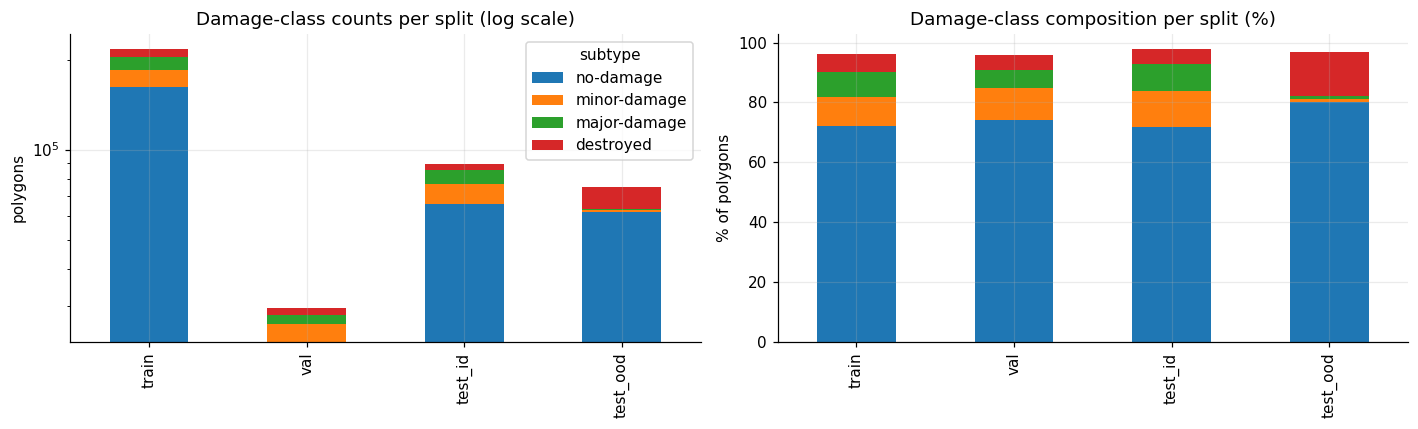

train imbalance ratio (majority / minority): 11.6x


In [14]:
def class_table(df, by):
    """Counts and row-normalised percentages of damage classes, grouped by `by`."""
    ct = pd.crosstab(df[by], df.subtype).reindex(columns=DAMAGE_CLASSES + [UNCLASSIFIED],
                                                 fill_value=0)
    pct = ct.div(ct.sum(axis=1).clip(lower=1), axis=0) * 100
    return ct, pct


ct_split, pct_split = class_table(buildings, "split")
ct_split = ct_split.reindex(SPLITS, fill_value=0)
pct_split = pct_split.reindex(SPLITS, fill_value=0)

print("building polygons per split x damage class")
display(ct_split.assign(total=ct_split.sum(axis=1)))
print("row-normalised %")
display(pct_split.round(2))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
ct_split[DAMAGE_CLASSES].plot(kind="bar", stacked=True, ax=axes[0])
axes[0].set_title("Damage-class counts per split (log scale)")
axes[0].set_yscale("log"); axes[0].set_ylabel("polygons"); axes[0].set_xlabel("")
pct_split[DAMAGE_CLASSES].plot(kind="bar", stacked=True, ax=axes[1], legend=False)
axes[1].set_title("Damage-class composition per split (%)")
axes[1].set_ylabel("% of polygons"); axes[1].set_xlabel("")
plt.tight_layout(); plt.show()

imb = ct_split.loc["train", DAMAGE_CLASSES]
print(f"train imbalance ratio (majority / minority): {imb.max() / max(imb.min(), 1):.1f}x")

**What we see.** `no-damage` is 72.0% of training polygons and the rarest class is 11.6× smaller.
The composition differs sharply by split — `test_ood` is 80.2 / 0.9 / 0.9 / 14.7 % against
72.0 / 9.7 / 8.4 / 6.2 % in train.

**Why it matters.** Accuracy is close to useless here: always predicting `no-damage` scores 0.72 on
train while producing a damage map that never flags damage. **Macro-F1 and per-class recall decide
everything**, including model selection.

**Downstream.**
1. Inverse-frequency class weights from `train` only — they came out 0.33 / 2.38 / 2.91 / 4.92.
2. Checkpointing and early stopping key on **val macro-F1**, not accuracy.
3. Confusion matrices are reported raw *and* row-normalised, because raw counts hide the minority
   classes completely.

Weighting was chosen over resampling: oversampling would repeat the same few destroyed buildings
many times per epoch and invite memorisation, undersampling would discard most of the majority
signal. Weighting keeps every sample once and changes only its gradient contribution.

### 3.2 Class distribution per disaster event — the transfer question, quantified

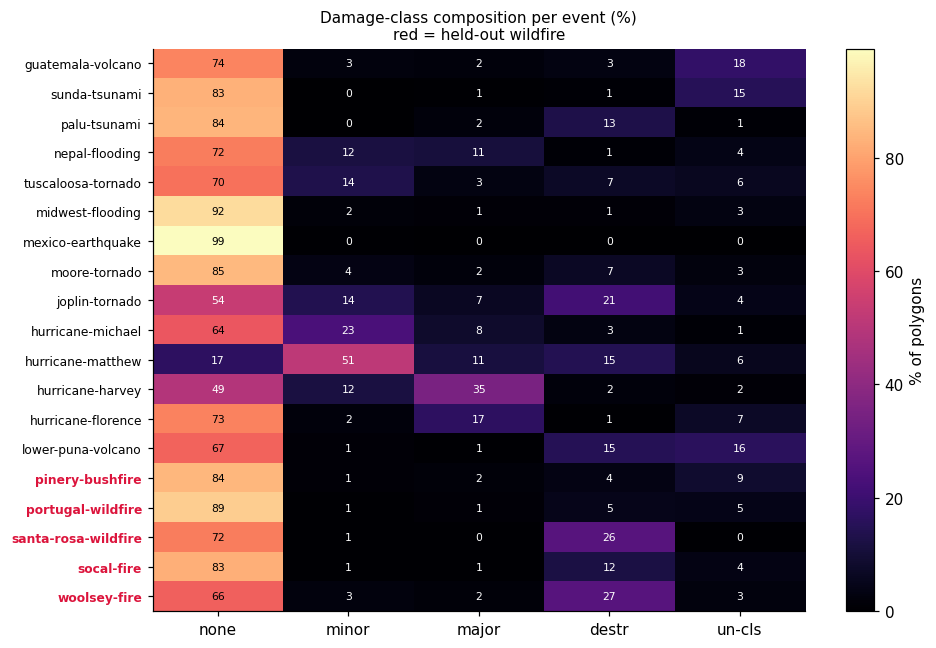

,non-fire events (train domain),wildfire events (OOD domain)
subtype,,
no-damage,70.2,78.8
minor-damage,9.9,1.2
major-damage,7.2,1.1
destroyed,6.5,14.8


In [15]:
ct_dis, pct_dis = class_table(buildings, "disaster")
order = (scenes.groupby("disaster").is_fire.first().sort_values().index.tolist())
pct_dis = pct_dis.reindex(order)

fig, ax = plt.subplots(figsize=(9, 6))
im = ax.imshow(pct_dis[DAMAGE_CLASSES + [UNCLASSIFIED]].values, cmap="magma", aspect="auto")
ax.set_xticks(range(5)); ax.set_xticklabels(SHORT + ["un-cls"])
ax.set_yticks(range(len(pct_dis))); ax.set_yticklabels(pct_dis.index, fontsize=8)
for i, ev in enumerate(pct_dis.index):
    if ev in fire_events:
        ax.get_yticklabels()[i].set_color("crimson")
        ax.get_yticklabels()[i].set_fontweight("bold")
    for j in range(5):
        v = pct_dis.iloc[i, j]
        ax.text(j, i, f"{v:.0f}", ha="center", va="center", fontsize=7,
                color="white" if v < 55 else "black")
ax.set_title("Damage-class composition per event (%)\nred = held-out wildfire", fontsize=10)
ax.grid(False); plt.colorbar(im, label="% of polygons"); plt.tight_layout(); plt.show()

fire_mix = pct_dis.loc[pct_dis.index.isin(fire_events), DAMAGE_CLASSES].mean()
nonfire_mix = pct_dis.loc[~pct_dis.index.isin(fire_events), DAMAGE_CLASSES].mean()
display(pd.DataFrame({"non-fire events (train domain)": nonfire_mix.round(1),
                      "wildfire events (OOD domain)": fire_mix.round(1)}))

**What we see.** The class mix is imbalanced *differently in every event*, and the fire rows are
qualitatively different from the rest:

| | no-damage | minor | major | destroyed |
|---|---|---|---|---|
| non-fire events | 70.2 | 9.9 | 7.2 | 6.5 |
| wildfire events | 78.8 | **1.2** | **1.1** | **14.8** |

Intermediate damage nearly vanishes under fire while `destroyed` more than doubles. Individual
events vary wildly too — `mexico-earthquake` is 99% undamaged, `hurricane-matthew` is 51% minor.

**Why it matters.** Fire produces a bimodal outcome: a building is untouched or it is gone. A model
that learns the hurricane prior will be systematically miscalibrated on fire even if its visual
features transfer perfectly.

**Downstream.** This predicts *what kind* of failure to expect in section 9. A pure prior shift
produces errors with a consistent direction; failed features produce diffuse errors. The last cell
of section 9 measures exactly that, and it is the difference between "recalibrate the thresholds"
and "this approach does not deploy on an unseen disaster".

### 3.3 Buildings per scene — and the tier3 empty-tile problem

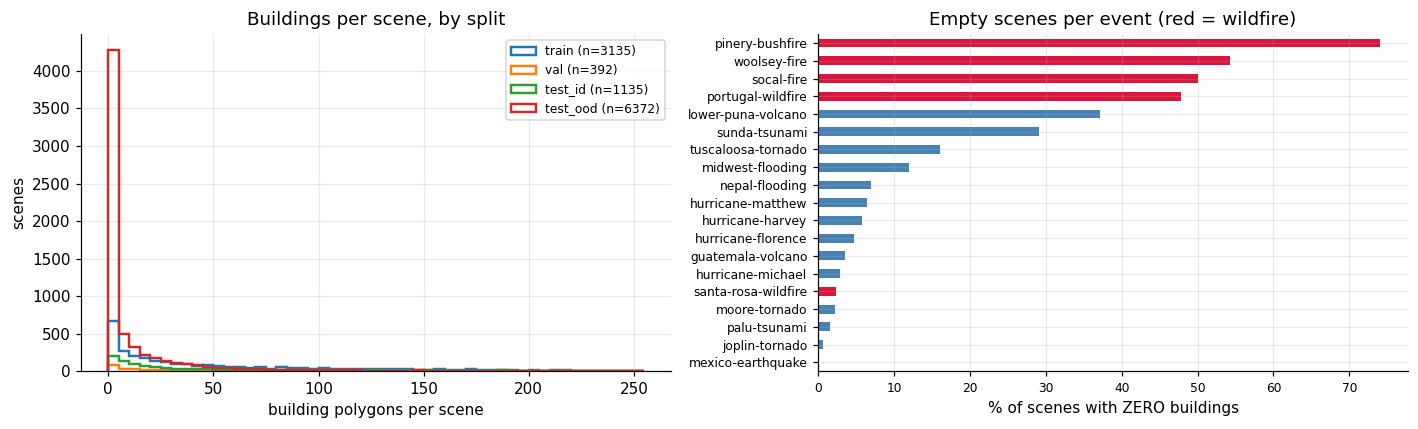

,scenes,empty_scenes,median_buildings,total_buildings,empty_%
split,,,,,
train,3135,306,29.0,225506,9.8
val,392,43,31.5,30794,11.0
test_id,1135,61,26.0,91755,5.4
test_ood,6372,3448,0.0,77313,54.1


In [16]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for sp in SPLITS:
    v = scene_meta.loc[scene_meta.split == sp, "n_buildings"]
    axes[0].hist(v, bins=np.arange(0, 260, 5), histtype="step", lw=1.6, label=f"{sp} (n={len(v)})")
axes[0].set(xlabel="building polygons per scene", ylabel="scenes",
            title="Buildings per scene, by split"); axes[0].legend(fontsize=8)

empty = (scene_meta.assign(empty=scene_meta.n_buildings.eq(0))
                   .groupby("disaster").empty.mean().mul(100).sort_values())
empty.plot(kind="barh", ax=axes[1],
           color=["crimson" if d in fire_events else "steelblue" for d in empty.index])
axes[1].set(xlabel="% of scenes with ZERO buildings", ylabel="",
            title="Empty scenes per event (red = wildfire)")
axes[1].tick_params(labelsize=8)
plt.tight_layout(); plt.show()

summary = (scene_meta.groupby("split")
           .agg(scenes=("scene_id", "size"),
                empty_scenes=("n_buildings", lambda s: int((s == 0).sum())),
                median_buildings=("n_buildings", "median"),
                total_buildings=("n_buildings", "sum"))
           .reindex(SPLITS))
summary["empty_%"] = (100 * summary.empty_scenes / summary.scenes).round(1)
display(summary)

**What we see.** Empty scenes are common and extremely event-dependent:

| split | scenes | empty | median buildings |
|---|---|---|---|
| train | 3,135 | 9.8% | 29 |
| val | 392 | 11.0% | 31.5 |
| test_id | 1,135 | 5.4% | 26 |
| test_ood | 6,372 | **54.1%** | **0** |

The tier3 fire events top the chart (`pinery-bushfire` highest) — they cover large stretches of
forest and scrubland.

**Why it matters.** An empty scene yields zero samples but still costs a full 1024×1024 PNG decode.
Sampling wildfire scenes uniformly would have spent most of the OOD budget on empty forest.

**Downstream.** Section 5.2 samples only scenes with at least `MIN_BUILDINGS_PER_SCENE` polygons.
This is a *sampling* decision, not a cleaning one — nothing is deleted, and the same rule is applied
to all four splits so it cannot tilt the ID→OOD comparison.

### 3.4 Building footprint geometry — this is what sets `PATCH_SIZE`

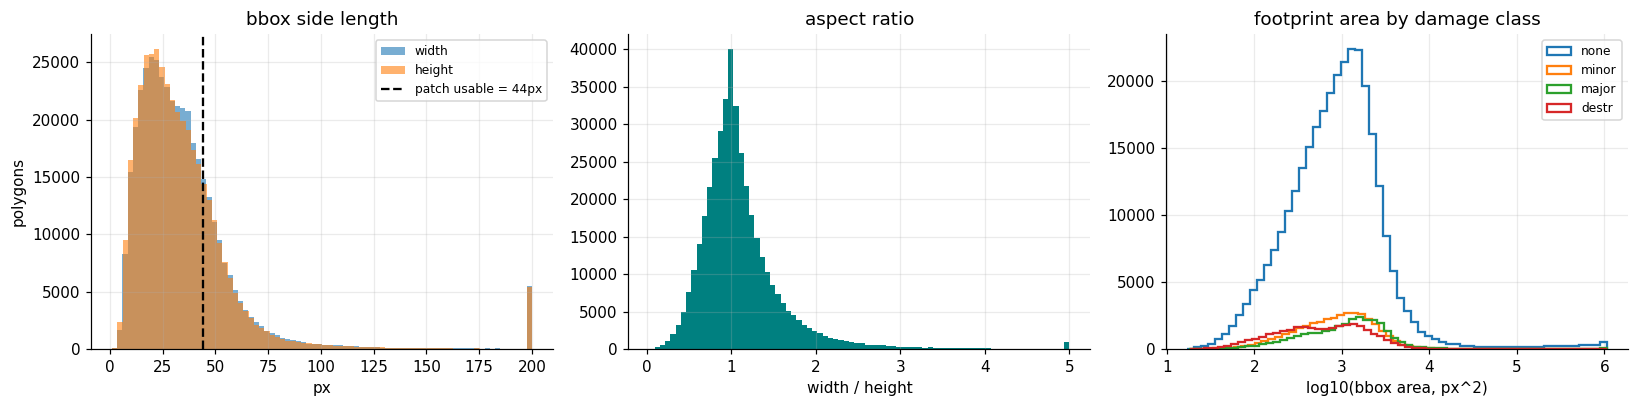

percentiles of max(bbox width, height), px:


,px
0.50,35.0
0.75,48.3
0.90,63.9
0.95,82.1
0.99,349.1


footprints with a side < 8px : 14,458 (3.51%)


In [17]:
bb = buildings[buildings.label.notna()]
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))

axes[0].hist(np.clip(bb.bw, 0, 200), bins=80, alpha=.6, label="width")
axes[0].hist(np.clip(bb.bh, 0, 200), bins=80, alpha=.6, label="height")
axes[0].axvline(PATCH_SIZE - 2 * BBOX_PAD, color="k", ls="--",
                label=f"patch usable = {PATCH_SIZE - 2 * BBOX_PAD}px")
axes[0].set(xlabel="px", ylabel="polygons", title="bbox side length"); axes[0].legend(fontsize=8)

axes[1].hist(np.clip(bb.aspect, 0, 5), bins=80, color="teal")
axes[1].set(xlabel="width / height", title="aspect ratio")

for c in range(NUM_CLASSES):
    v = bb.loc[bb.label == c, "barea"]
    axes[2].hist(np.log10(v.clip(lower=1)), bins=60, histtype="step", lw=1.5, label=SHORT[c])
axes[2].set(xlabel="log10(bbox area, px^2)", title="footprint area by damage class")
axes[2].legend(fontsize=8)
plt.tight_layout(); plt.show()

q = bb[["bw", "bh"]].max(axis=1).quantile([.5, .75, .9, .95, .99]).round(1)
print("percentiles of max(bbox width, height), px:")
display(q.rename("px").to_frame())
print(f"footprints with a side < {MIN_BBOX_PX}px : "
      f"{int(((bb.bw < MIN_BBOX_PX) | (bb.bh < MIN_BBOX_PX)).sum()):,} "
      f"({100 * ((bb.bw < MIN_BBOX_PX) | (bb.bh < MIN_BBOX_PX)).mean():.2f}%)")

**What we see.** Footprints are small: median longest side 35 px, 90th percentile 64 px, with a thin
tail out to 349 px at the 99th. Only 3.51% of footprints have a side under 8 px.

**Why it matters.**
- `PATCH_SIZE = 64` covers roughly 90% of buildings at close to native resolution. Larger mostly
  upsamples empty ground at quadratic cost; smaller destroys the roof texture that separates
  `minor` from `major`.
- The crop is resized to a square, so aspect ratio is not preserved — an accepted trade-off, and the
  measured distribution is close to square anyway.
- `BBOX_PAD = 10` px is what lets the model see the surroundings: debris, scorch marks, standing
  water. Damage is often more visible around a building than on it.

**Downstream.** Rule 4.5 drops the sub-8 px footprints — after padding and upscaling they are
interpolation artefacts, not observations of a building.

### 3.5 Capture metadata — the hidden domain shift

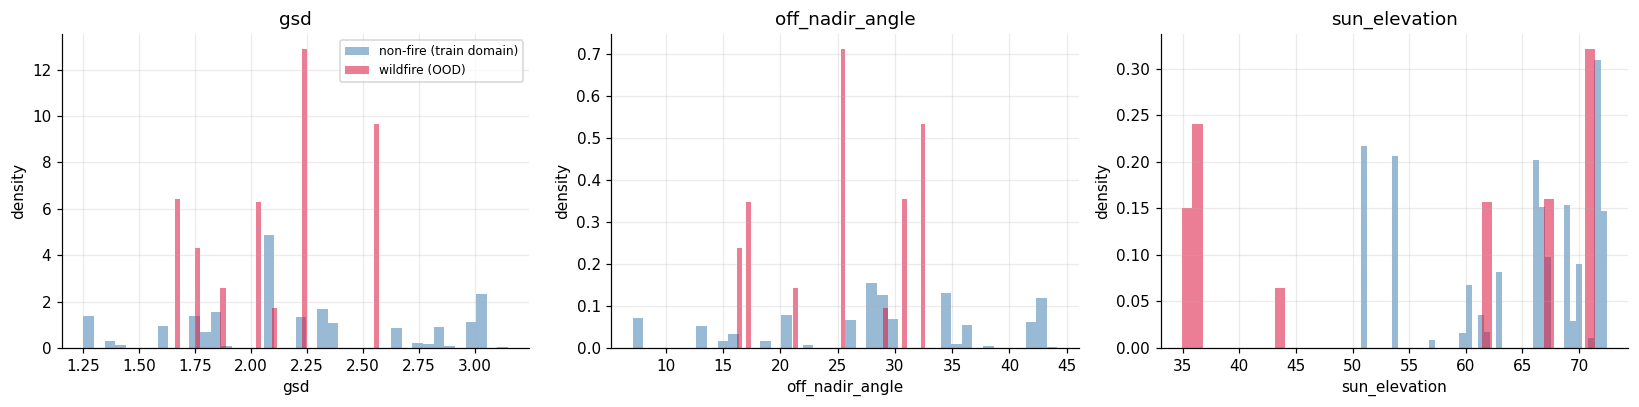

gsd       off_nadir_angle       sun_elevation       
                mean   std            mean   std          mean    std
domain                                                               
non-fire        2.21  0.52           28.53  9.87         64.44   7.45
wildfire (OOD)  2.12  0.31           25.60  5.98         55.03  15.92

In [18]:
meta_cols = ["gsd", "off_nadir_angle", "sun_elevation"]
geo = scene_meta.dropna(subset=meta_cols)

fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
for ax, c in zip(axes, meta_cols):
    for grp, lbl, col in [(geo[~geo.disaster.isin(fire_events)], "non-fire (train domain)", "steelblue"),
                          (geo[geo.disaster.isin(fire_events)], "wildfire (OOD)", "crimson")]:
        ax.hist(grp[c], bins=40, alpha=.55, label=lbl, color=col, density=True)
    ax.set(xlabel=c, ylabel="density", title=c)
axes[0].legend(fontsize=8)
plt.tight_layout(); plt.show()

display(geo.assign(domain=np.where(geo.disaster.isin(fire_events), "wildfire (OOD)", "non-fire"))
           .groupby("domain")[meta_cols].agg(["mean", "std"]).round(2))

**What we see.** Capture geometry is not identical between the two domains:

| | GSD | off-nadir | sun elevation |
|---|---|---|---|
| non-fire | 2.21 ± 0.52 | 28.5 ± 9.9 | 64.4 ± 7.5 |
| wildfire | 2.12 ± 0.31 | 25.6 ± 6.0 | **55.0 ± 15.9** |

GSD and off-nadir angle are close. **Sun elevation is not**: the wildfire mean is 9° lower with more
than twice the spread, and the histogram shows a fire mode near 35° that has no counterpart in
training. Low sun means long shadows and a different look for the same structure.

**Why it matters.** Part of any transfer gap could be acquisition geometry rather than fire damage
looking different. Claiming "damage does not transfer across disaster types" when the real driver is
shadow length would be unsupported.

**The honest caveat.** The histograms are spiky because every scene in an event shares one
acquisition. Statistically this is **19 points, not 11,034**, and the geometry is fully confounded
with event identity — "wildfire" and "the captures that happen to be wildfire" cannot be separated
on this data. That belongs in the limitations section rather than being quietly ignored.

**Downstream.** Flip, 90° rotation and scale augmentation become an evidence-backed robustness
measure rather than a reflex.

*(Note: the `gsd` field reads ~2.2, while the xBD paper quotes sub-metre imagery — the field most
likely records pre-pansharpening GSD. Do not quote both figures side by side without checking. The
comparison between domains is still valid; only the absolute unit is uncertain.)*

### 3.6 Image properties — dimensions, channels, and readability

Verified on a random sample of scenes rather than all 22,068 files: decoding every 1024×1024 PNG
would take longer than the rest of the notebook combined, and a random sample is enough to confirm a
uniform format (and to *detect* it if the format is not uniform).

In [19]:
set_seed()
per_split = max(QC_SAMPLE_SCENES // len(SPLITS), 1)
qc_scenes = pd.concat([g.sample(min(len(g), per_split), random_state=SEED)
                       for _, g in scenes.groupby("split")], ignore_index=True)
print(f"QC sample: {len(qc_scenes)} scenes ({2 * len(qc_scenes)} image files)")


def probe_image(path):
    """Open header only where possible; return format facts plus any error."""
    try:
        with Image.open(path) as im:
            w, h, mode, fmt = im.width, im.height, im.mode, im.format
        return {"path": path, "w": w, "h": h, "mode": mode, "format": fmt, "error": None}
    except Exception as e:
        return {"path": path, "w": None, "h": None, "mode": None, "format": None,
                "error": f"{type(e).__name__}: {e}"}


with ThreadPoolExecutor(max_workers=IO_WORKERS) as ex:
    probes = pd.DataFrame(list(ex.map(probe_image,
                                      qc_scenes.img_pre.tolist() + qc_scenes.img_post.tolist())))

print("\nresolution x mode x format:")
display(probes.groupby(["w", "h", "mode", "format"], dropna=False).size().rename("files").to_frame())
print("header-level read errors:", int(probes.error.notna().sum()))
if probes.error.notna().any():
    display(probes[probes.error.notna()].head(10))

QC sample: 400 scenes (800 image files)

resolution x mode x format:


,,,,files
w,h,mode,format,
1024,1024,RGB,PNG,800


header-level read errors: 0


**What we see.** All 800 sampled files are 1024×1024 RGB PNG, 8-bit, with zero read errors.

**Why it matters.** Two items the project brief lists as cleaning work are already done by the
dataset: there is no resolution standardisation and no band alignment to perform. More importantly,
**pre and post tiles are already co-registered** by the xBD authors — pixel (x, y) is the same ground
location in both — which is what makes cropping the *same* box from both images valid. Without that
the entire siamese design would be comparing different places.

**Downstream.** Preprocessing reduces to: crop by bbox, resize, scale to [0,1], ImageNet-normalise.
No warping, no resampling.

### 3.7 Representative samples — what the four classes actually look like

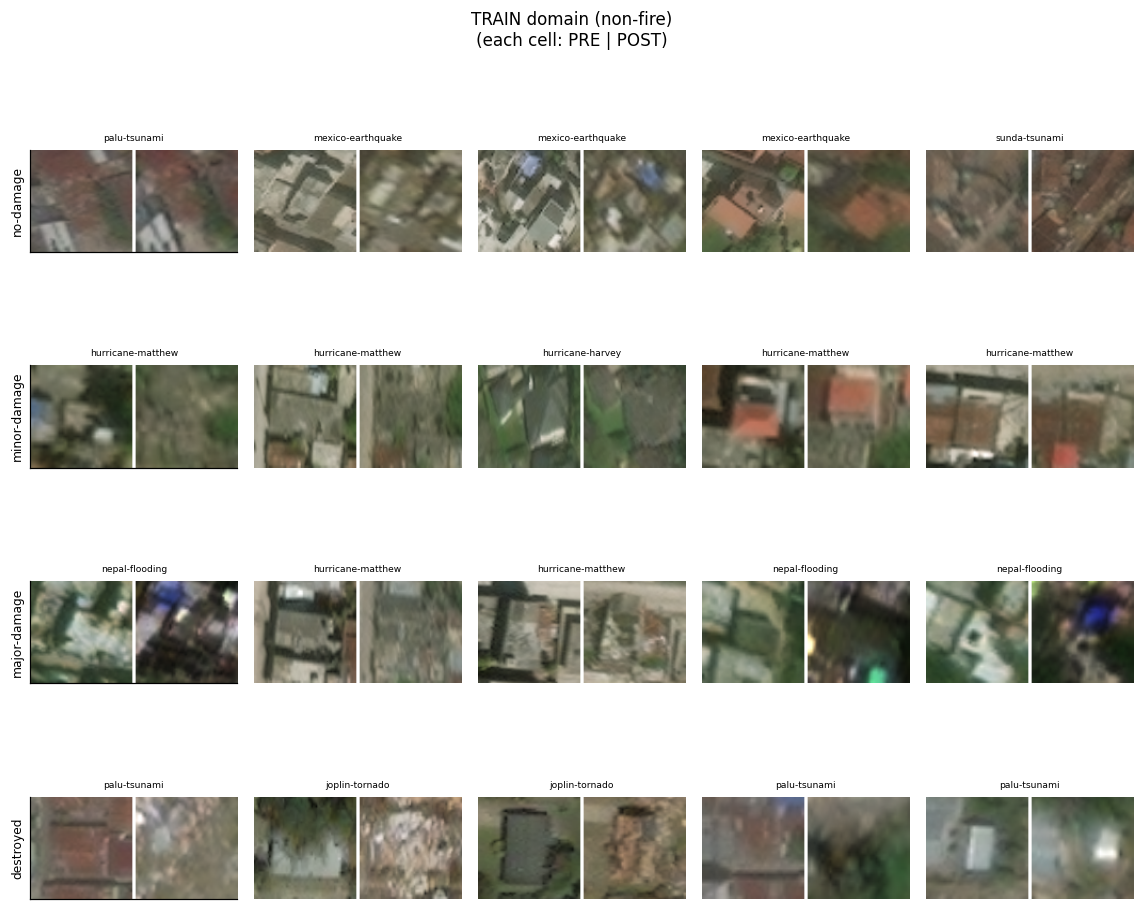

decoded 18 tiles for this figure


In [20]:
def load_patch(img_path, box, pad=BBOX_PAD, size=PATCH_SIZE, full=None):
    """Crop one padded, resized RGB patch. `full` lets a caller reuse an already-open image."""
    im = full if full is not None else Image.open(img_path).convert("RGB")
    minx, miny, maxx, maxy = box
    W, H = im.size
    l, t = max(0, int(minx) - pad), max(0, int(miny) - pad)
    r, b = min(W, int(maxx) + pad), min(H, int(maxy) + pad)
    if r - l < 2 or b - t < 2:
        return None
    return np.asarray(im.crop((l, t, r, b)).resize((size, size), Image.BILINEAR), np.uint8)


def show_examples(pool, title, n_per_class=5, size=96, scenes_per_class=3):
    """Grid: rows = damage class, columns = examples, each cell = pre | post side by side.

    I/O is the bottleneck, not plotting: `/kaggle/input` is a network-backed mount where a cold
    1024x1024 tile can take seconds. Drawing 5 independent random buildings per class would touch
    10 different tiles per row. Instead we pick a few scenes that are RICH in that class (one per
    event, to keep the columns visually diverse), decode each tile once and reuse it for every
    example it contributes - roughly 24 reads for the whole figure instead of 40.
    """
    cache = {}

    def tile(path):
        if path not in cache:
            cache[path] = Image.open(path).convert("RGB")
        return cache[path]

    fig, axes = plt.subplots(NUM_CLASSES, n_per_class,
                             figsize=(2.1 * n_per_class, 2.3 * NUM_CLASSES), squeeze=False)
    for c in range(NUM_CLASSES):
        for j in range(n_per_class):
            axes[c, j].axis("off"); axes[c, j].grid(False)

        cand = pool[pool.label == c]
        if cand.empty:
            continue
        # richest scene per event, so one decode serves several columns
        ranked = (cand.groupby(["scene_id", "disaster"]).size().rename("n").reset_index()
                      .sort_values("n", ascending=False)
                      .drop_duplicates("disaster").head(scenes_per_class))
        sub = cand[cand.scene_id.isin(ranked.scene_id)]
        picks = sub.sample(min(n_per_class, len(sub)), random_state=SEED)

        for j, (_, r) in enumerate(picks.iterrows()):
            box = (r.minx, r.miny, r.maxx, r.maxy)
            pre = load_patch(None, box, size=size, full=tile(r.img_pre))
            post = load_patch(None, box, size=size, full=tile(r.img_post))
            if pre is None or post is None:
                continue
            axes[c, j].imshow(np.concatenate(
                [pre, np.full((size, 3, 3), 255, np.uint8), post], axis=1))
            axes[c, j].set_title(r.disaster, fontsize=6)

        if len(picks):
            axes[c, 0].axis("on"); axes[c, 0].set_xticks([]); axes[c, 0].set_yticks([])
            axes[c, 0].set_ylabel(DAMAGE_CLASSES[c], fontsize=8)

    fig.suptitle(f"{title}\n(each cell: PRE | POST)", fontsize=11)
    plt.tight_layout(); plt.show()
    print(f"decoded {len(cache)} tiles for this figure")


sample_pool = (buildings[buildings.label.notna()]
               .merge(scenes[["scene_id", "img_pre", "img_post"]], on="scene_id"))
set_seed()
if SHOW_EXAMPLE_GRIDS:
    show_examples(sample_pool[sample_pool.split == "train"], "TRAIN domain (non-fire)")
else:
    print("skipped (SHOW_EXAMPLE_GRIDS = False)")

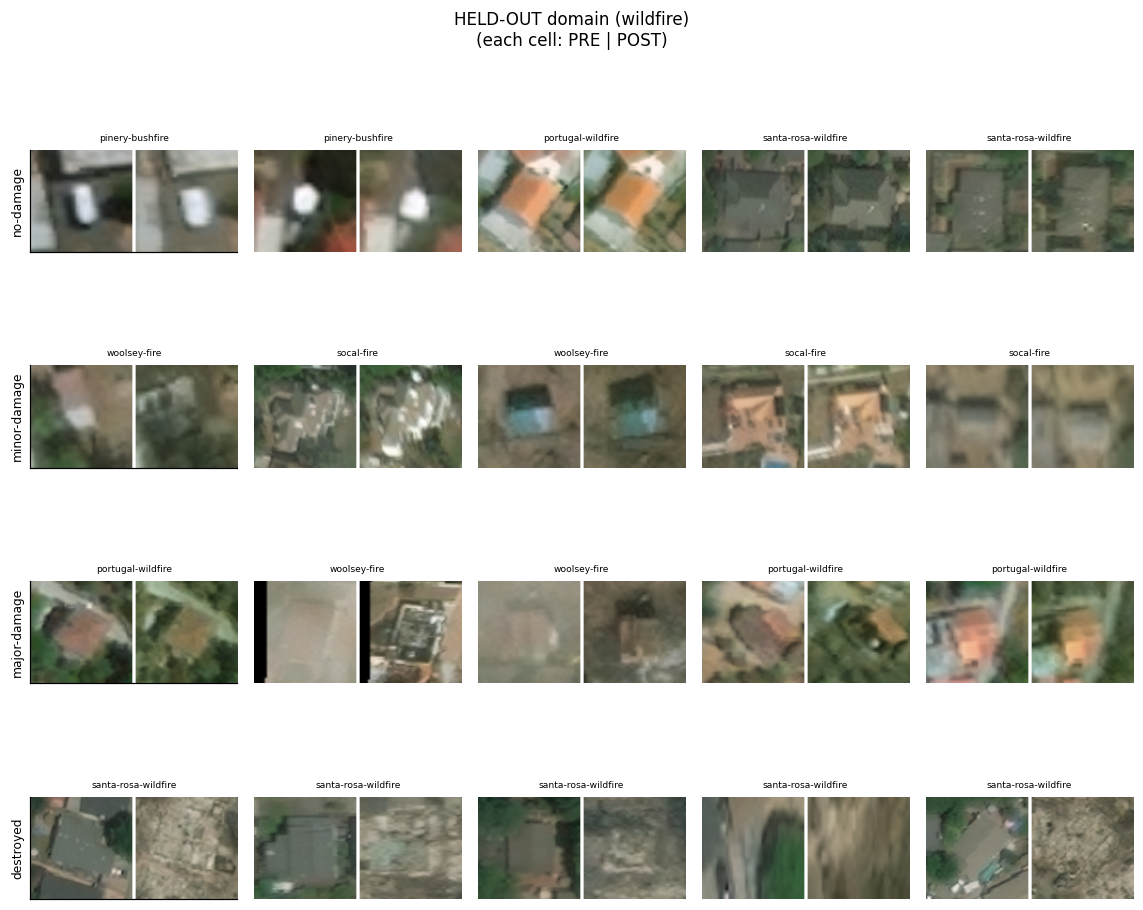

decoded 16 tiles for this figure


In [21]:
if SHOW_EXAMPLE_GRIDS:
    show_examples(sample_pool[sample_pool.split == "test_ood"], "HELD-OUT domain (wildfire)")
else:
    print("skipped (SHOW_EXAMPLE_GRIDS = False)")

**What we see.** The two domains are visibly different problems. Non-fire post images usually retain
the structure with altered geometry — torn roofs, debris, standing water. Wildfire damage collapses
buildings to a uniform grey scar with the footprint faintly visible, while undamaged buildings often
sit in surroundings that changed completely (scorched vegetation) with the roof untouched.

**The prediction this generates.** A change-detection model learns "the scene changed" ⇒ "the
building is damaged". Under wildfire the *context* changes for undamaged buildings too, so we should
expect **false positives on `no-damage`** in `test_ood`.

**Downstream.** This is falsifiable and section 9 tests it directly. → **Confirmed: 37.2% of truly
undamaged wildfire buildings were flagged as damaged.** It also justifies keeping `BBOX_PAD` modest —
more surrounding context makes the model more sensitive to exactly the signal that misleads it here.

## 4 · Data cleaning and quality diagnostics

**Operating principle:** nothing is removed silently. Every rule below states *what* it removes,
*why*, *at what threshold*, and *how many* samples it costs. Rules whose thresholds cannot be
justified from the data produce a **flag and a gallery for manual review** instead of a deletion.

We accumulate decisions in a ledger and print it at the end of the section.

In [22]:
CLEANING_LEDGER = []

def log_rule(rule, scope, removed, kept, why, threshold=""):
    CLEANING_LEDGER.append({"rule": rule, "scope": scope, "removed": int(removed),
                            "kept": int(kept), "threshold": str(threshold), "rationale": why})
    pct = 100 * removed / max(removed + kept, 1)
    print(f"[{rule}] removed {removed:,} ({pct:.2f}%), kept {kept:,}  | {threshold}")

### 4.1 Rule — missing or unpaired files

A scene is usable only if **pre image, post image and post label** all exist. A missing pre image
makes change detection impossible; a missing post label leaves the sample unlabelled.

In [23]:
paths_needed = ["img_pre", "img_post", "lab_post"]
exists = pd.DataFrame({c: scenes[c].map(os.path.exists) for c in paths_needed})
scenes["files_ok"] = exists.all(axis=1)

print("per-file existence:")
display(exists.sum().rename("present").to_frame().assign(missing=len(scenes) - exists.sum()))
log_rule("4.1 missing/unpaired files", "scenes",
         removed=(~scenes.files_ok).sum(), kept=scenes.files_ok.sum(),
         why="change detection needs pre+post+label; an incomplete scene cannot be used",
         threshold="all three files must exist")

if (~scenes.files_ok).any():
    display(scenes.loc[~scenes.files_ok, ["scene_id", "origin", "split"]].head(20))

per-file existence:


,present,missing
img_pre,11034,0
img_post,11034,0
lab_post,11034,0


[4.1 missing/unpaired files] removed 0 (0.00%), kept 11,034  | all three files must exist


### 4.2 Rule — corrupted / unreadable files

Two distinct failure modes, checked separately:
- **label JSON** unparseable (already captured during the scan in 2.3)
- **image PNG** truncated or with a broken CRC — a header probe is not enough, so we fully decode
  the QC sample. `LOAD_TRUNCATED_IMAGES` was set to `False` at import precisely so these raise.

In [24]:
def verify_decode(path):
    """Fully decode an image; returns None on success, else the error string."""
    try:
        with Image.open(path) as im:
            im.load()
        return None
    except Exception as e:
        return f"{type(e).__name__}: {e}"


with ThreadPoolExecutor(max_workers=IO_WORKERS) as ex:
    decode_files = qc_scenes.img_pre.tolist() + qc_scenes.img_post.tolist()
    decode_errs = list(ex.map(verify_decode, decode_files))

n_bad_img = sum(e is not None for e in decode_errs)
print(f"fully decoded {len(decode_files)} images from the QC sample")
for f, e in zip(decode_files, decode_errs):
    if e:
        print("  CORRUPT:", Path(f).name, "->", e)

log_rule("4.2a corrupted images", f"QC sample of {len(decode_files)} images",
         removed=n_bad_img, kept=len(decode_files) - n_bad_img,
         why="a truncated PNG raises mid-training and kills the run",
         threshold="PIL full decode must succeed")
log_rule("4.2b unreadable labels", "all scenes",
         removed=scene_meta.label_error.notna().sum(),
         kept=scene_meta.label_error.isna().sum(),
         why="an unparseable JSON yields no labels for the whole scene",
         threshold="json.loads must succeed")

print("\nNote: full decoding is done on a sample only. The patch-extraction loop (section 6) wraps "
      "every read in try/except and reports any file that fails there, so the remaining scenes are "
      "covered without a second full pass over 22,068 PNGs.")

fully decoded 800 images from the QC sample
[4.2a corrupted images] removed 0 (0.00%), kept 800  | PIL full decode must succeed
[4.2b unreadable labels] removed 0 (0.00%), kept 11,034  | json.loads must succeed

Note: full decoding is done on a sample only. The patch-extraction loop (section 6) wraps every read in try/except and reports any file that fails there, so the remaining scenes are covered without a second full pass over 22,068 PNGs.


### 4.3 Diagnostic — smoke / cloud occlusion

This is the team's open question: *"we need to remove images that are totally covered by smoke."*

**Finding: xBD has no occlusion label.** There is no cloud, smoke or quality field anywhere in the
label JSON — the `metadata` block contains only capture geometry (verified in 2.2), and `splits.csv`
carries no such column either. So an automatic rule cannot be grounded in ground truth.

**The closest thing to a real label is `subtype = "un-classified"`.** Annotators used it when a
building could not be assessed, and occlusion is one of the main reasons that happens. It is a
*proxy*, not an occlusion label — it also covers ambiguous or partially-visible structures — but it
is a human judgement recorded in the ground truth, which is strictly better than a pixel threshold
we invented. We rank scenes by it below and then check the ranking against the pixels.

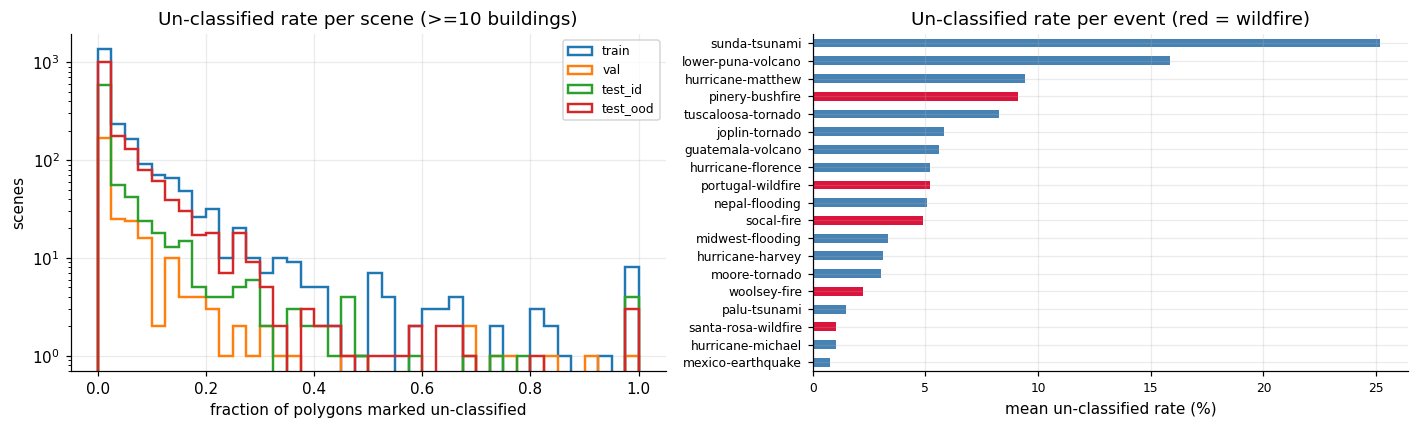

scenes with >= 50% un-classified:    69  (1.42% of scenes with >=10 buildings)
scenes with >= 80% un-classified:    26  (0.53% of scenes with >=10 buildings)
scenes with >= 95% un-classified:    16  (0.33% of scenes with >=10 buildings)


In [25]:
unc_stats = scene_meta[scene_meta.n_buildings >= 10].copy()
unc_stats["unc_frac"] = unc_stats.n_unclassified / unc_stats.n_buildings

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for sp in SPLITS:
    v = unc_stats.loc[unc_stats.split == sp, "unc_frac"]
    if len(v):
        axes[0].hist(v, bins=np.linspace(0, 1, 41), histtype="step", lw=1.6, label=sp)
axes[0].set(xlabel="fraction of polygons marked un-classified", ylabel="scenes",
            yscale="log", title="Un-classified rate per scene (>=10 buildings)")
axes[0].legend(fontsize=8)

by_ev = unc_stats.groupby("disaster").unc_frac.mean().mul(100).sort_values()
by_ev.plot(kind="barh", ax=axes[1],
           color=["crimson" if d in fire_events else "steelblue" for d in by_ev.index])
axes[1].set(xlabel="mean un-classified rate (%)", ylabel="",
            title="Un-classified rate per event (red = wildfire)")
axes[1].tick_params(labelsize=8)
plt.tight_layout(); plt.show()

for thr in (0.5, 0.8, 0.95):
    n = int((unc_stats.unc_frac >= thr).sum())
    print(f"scenes with >= {thr:.0%} un-classified: {n:5d}  ({100 * n / len(unc_stats):.2f}% of scenes with >=10 buildings)")

### 4.3b — do the pixels agree with the annotators?

If `un-classified` really tracks occlusion, then high-rate scenes should also look occluded to
simple image statistics. Smoke and thin cloud on 3-band optical imagery are **bright, low-contrast,
low-saturation, and edge-poor**. We compute those four statistics on the post-disaster tile for the
QC sample plus every high-`un-classified` scene, and test whether the two signals correlate.

If they do not correlate, the honest conclusion is that neither signal is trustworthy alone — and we
say so rather than shipping a filter.

computed occlusion stats for 683 tiles in 4s

correlation of un-classified rate with image statistics (n=505):


,spearman rho
brightness,0.116
contrast,-0.035
saturation,-0.095
edges,-0.366


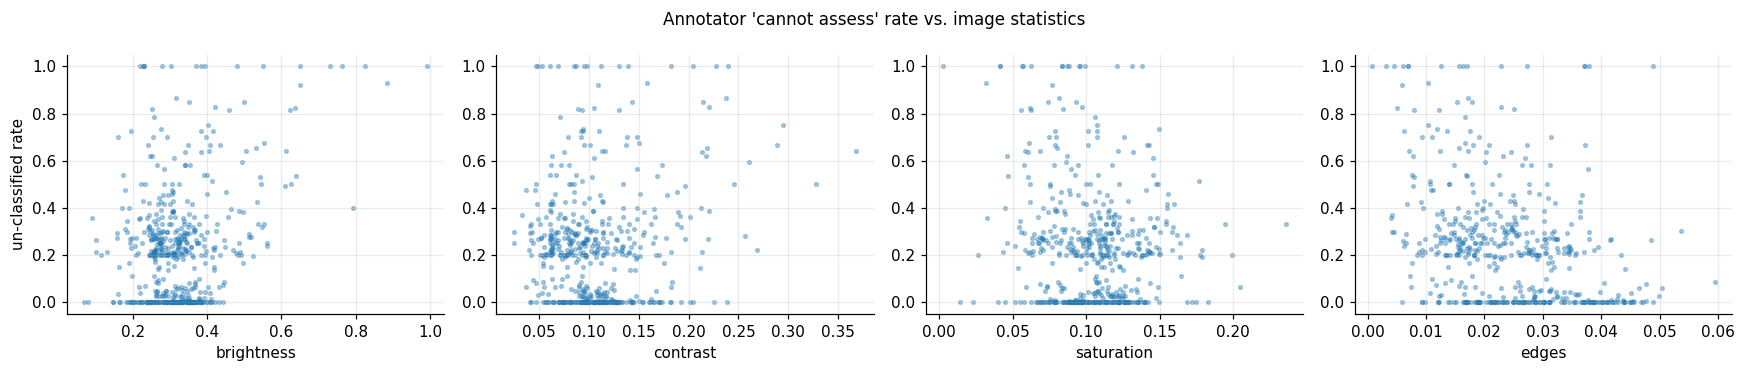

In [26]:
def occlusion_stats(path, side=256):
    """Cheap whole-tile occlusion statistics on a downscaled copy of the post image."""
    try:
        with Image.open(path) as im:
            a = np.asarray(im.convert("RGB").resize((side, side), Image.BILINEAR), np.float32) / 255.
    except Exception:
        return dict(brightness=np.nan, contrast=np.nan, saturation=np.nan, edges=np.nan)
    g = a.mean(axis=2)
    gy, gx = np.gradient(g)
    return dict(
        brightness=float(g.mean()),                                   # smoke/cloud raises this
        contrast=float(g.std()),                                      # and flattens this
        saturation=float((a.max(2) - a.min(2)).mean()),               # smoke is near-grey
        edges=float(np.hypot(gx, gy).mean()),                         # texture disappears
    )


unc_top = unc_stats.nlargest(300, "unc_frac").scene_id
qc_ids  = pd.Index(qc_scenes.scene_id).union(unc_top)
occ_src = scenes[scenes.scene_id.isin(qc_ids)].copy()

OCC_CACHE = CACHE / "occlusion.parquet"
if OCC_CACHE.exists():
    occ = pd.read_parquet(OCC_CACHE)
    print("loaded occlusion stats from cache")
else:
    t0 = time.time()
    with ThreadPoolExecutor(max_workers=IO_WORKERS) as ex:
        stats = list(ex.map(occlusion_stats, occ_src.img_post.tolist()))
    occ = pd.concat([occ_src[["scene_id", "disaster", "split", "img_pre", "img_post"]]
                     .reset_index(drop=True), pd.DataFrame(stats)], axis=1)
    occ.to_parquet(OCC_CACHE, index=False)
    print(f"computed occlusion stats for {len(occ)} tiles in {time.time() - t0:.0f}s")

occ = occ.merge(unc_stats[["scene_id", "unc_frac", "n_buildings"]], on="scene_id", how="left")
occ_c = occ.dropna(subset=["unc_frac", "brightness"])

print(f"\ncorrelation of un-classified rate with image statistics (n={len(occ_c)}):")
display(occ_c[["unc_frac", "brightness", "contrast", "saturation", "edges"]]
        .corr(method="spearman")["unc_frac"].drop("unc_frac").round(3).rename("spearman rho").to_frame())

fig, axes = plt.subplots(1, 4, figsize=(16, 3.4))
for ax, c in zip(axes, ["brightness", "contrast", "saturation", "edges"]):
    ax.scatter(occ_c[c], occ_c.unc_frac, s=6, alpha=.35)
    ax.set(xlabel=c, ylabel="un-classified rate" if c == "brightness" else "")
plt.suptitle("Annotator 'cannot assess' rate vs. image statistics", fontsize=11)
plt.tight_layout(); plt.show()

Top occlusion candidates for MANUAL review:


,scene_id,disaster,split,unc_frac,brightness,contrast,saturation,edges,occ_score
0,lower-puna-volcano_00000096,lower-puna-volcano,train,1.000,0.992,0.049,0.003,0.001,3.132
1,sunda-tsunami_00000081,sunda-tsunami,val,1.000,0.826,0.046,0.057,0.003,2.296
2,sunda-tsunami_00000110,sunda-tsunami,train,1.000,0.763,0.052,0.056,0.005,2.092
3,sunda-tsunami_00000147,sunda-tsunami,train,0.930,0.885,0.158,0.032,0.010,1.874
4,sunda-tsunami_00000038,sunda-tsunami,train,1.000,0.732,0.069,0.063,0.006,1.849
5,sunda-tsunami_00000017,sunda-tsunami,train,1.000,0.651,0.098,0.041,0.007,1.652
6,sunda-tsunami_00000058,sunda-tsunami,train,0.238,0.562,0.070,0.052,0.006,1.528
7,sunda-tsunami_00000078,sunda-tsunami,train,0.816,0.623,0.093,0.056,0.008,1.484
8,sunda-tsunami_00000036,sunda-tsunami,train,0.822,0.637,0.105,0.062,0.005,1.476
9,sunda-tsunami_00000074,sunda-tsunami,val,0.920,0.650,0.109,0.077,0.006,1.350


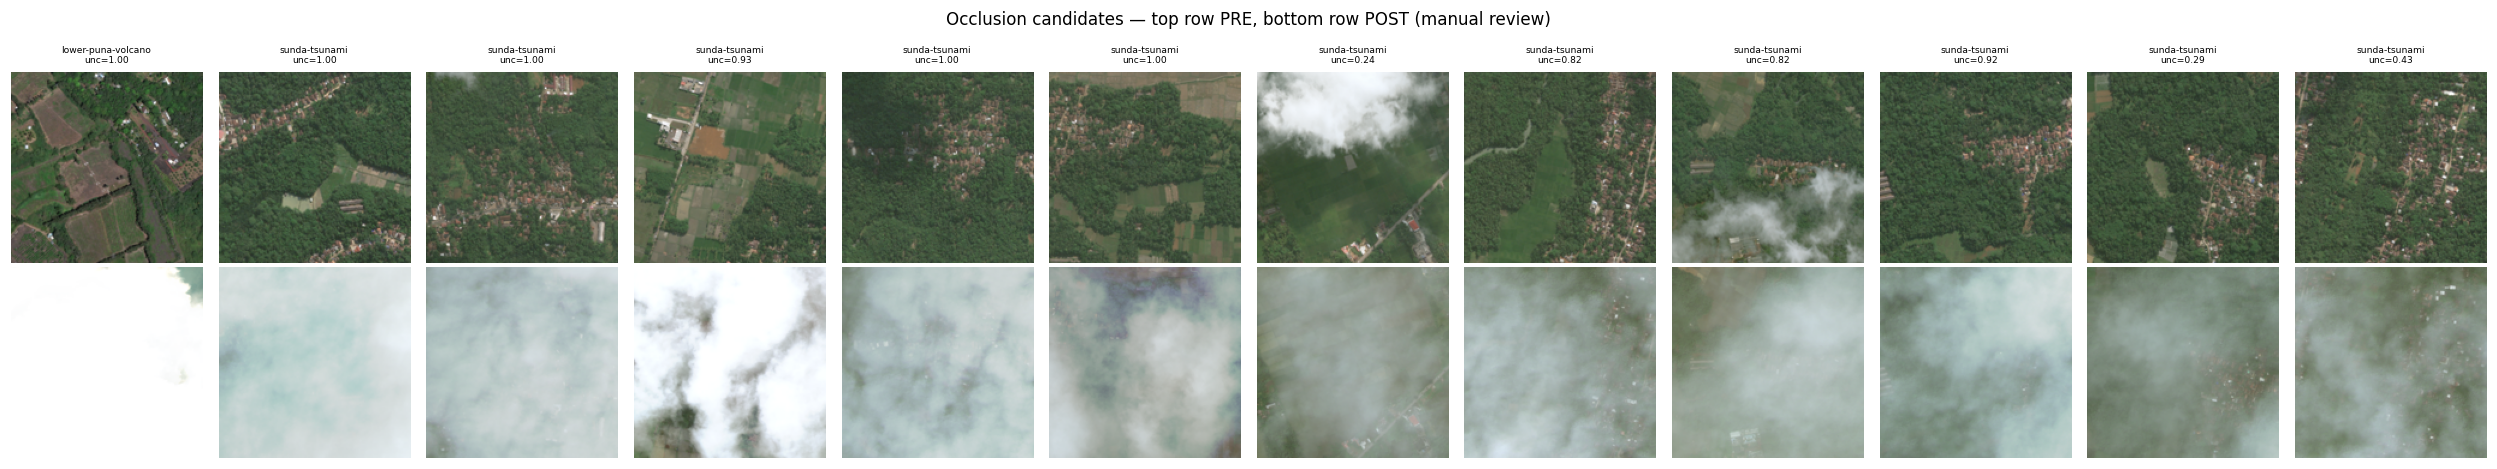

In [27]:
# ---------------------------------------------------------------- composite candidate score
# Ranking only. It is NOT used to delete anything; it selects what a human looks at.
z = lambda s: (s - s.mean()) / s.std(ddof=0)
occ["occ_score"] = (z(occ.brightness) - z(occ.contrast) - z(occ.saturation) - z(occ.edges)) / 4
cands = occ.dropna(subset=["occ_score"]).nlargest(OCCLUSION_TOP_N, "occ_score")

print("Top occlusion candidates for MANUAL review:")
display(cands[["scene_id", "disaster", "split", "unc_frac", "brightness",
               "contrast", "saturation", "edges", "occ_score"]].round(3).reset_index(drop=True))

n = max(min(OCCLUSION_TOP_N, len(cands)), 1)
fig, axes = plt.subplots(2, n, figsize=(1.9 * n, 4.4), squeeze=False)
for j in range(n):
    if j >= len(cands):
        axes[0, j].axis("off"); axes[1, j].axis("off")
        continue
    r = cands.iloc[j]
    for i, p in enumerate([r.img_pre, r.img_post]):
        ax = axes[i, j]; ax.axis("off"); ax.grid(False)
        try:
            with Image.open(p) as im:
                ax.imshow(im.convert("RGB").resize((160, 160)))
        except Exception:
            pass
    axes[0, j].set_title(f"{r.disaster}\nunc={r.unc_frac:.2f}" if pd.notna(r.unc_frac)
                         else r.disaster, fontsize=6)
axes[0, 0].set_ylabel("PRE"); axes[1, 0].set_ylabel("POST")
plt.suptitle("Occlusion candidates — top row PRE, bottom row POST (manual review)", fontsize=11)
plt.tight_layout(); plt.show()

**What we measured.**

| statistic | Spearman ρ with un-classified rate |
|---|---|
| edge density | **−0.366** |
| brightness | +0.116 |
| saturation | −0.095 |
| contrast | −0.035 |

Only **edge density** correlates meaningfully. Brightness is weak and contrast is essentially zero,
so the composite score is really measuring "texture-poor", not "bright and flat" as expected.

**What the gallery shows.** The top candidates are **not wildfire**. They are `sunda-tsunami` and
`lower-puna-volcano` tiles under thick cloud — the worst has brightness 0.99 with contrast 0.049,
which is a tile that is almost pure white. Flagged at the 98th percentile: 11 scenes in `train`,
3 in `val`, **0 in `test_id`, 0 in `test_ood`**.

**This reverses the concern we started with.** The team's worry was smoke hiding wildfire damage.
The measurement says the real occlusion in xBD is *cloud over tsunami and volcano scenes*, and it
sits in the training pool, not in either test set.

**Decision: nothing is removed.** Reasons, in order of weight:

1. **No ground truth to validate a threshold.** Any cut point would be tuned by eye on a handful of
   images. A rule that deletes data and cannot be validated is an unmeasurable bias.
2. **There is almost nothing to gain.** 14 flagged scenes out of 683 inspected, none in a test split.
   The effect on any reported number is negligible.
3. **Occlusion is part of the deployment problem.** A system running on real post-disaster imagery
   meets cloud and smoke. Deleting it measures a scenario that does not exist.
4. **A safer patch-level filter already exists** — section 6 rejects crops that are essentially pure
   white or pure black, applied identically to every split.

Candidates are exported to `occlusion_candidates.csv`. If the team wants removal, the defensible
route is to hand-label the top ~200, measure the score's false-positive rate, and report the result
both with and without the filter.

In [28]:
FLAG_THRESHOLD = occ.occ_score.quantile(0.98)      # flag only, no deletion
occ["occlusion_flag"] = occ.occ_score >= FLAG_THRESHOLD
occ[["scene_id", "disaster", "split", "unc_frac", "occ_score", "occlusion_flag"]] \
    .to_csv(WORK / "occlusion_candidates.csv", index=False)

flag_by_split = occ.groupby("split").occlusion_flag.agg(["sum", "size"])
flag_by_split.columns = ["flagged", "inspected"]
display(flag_by_split)

log_rule("4.3 smoke/cloud occlusion", "scenes", removed=0, kept=len(occ),
         why="no occlusion ground truth exists; removal would bias test_ood, the split under study",
         threshold=f"FLAGGED ONLY at occ_score >= p98 ({FLAG_THRESHOLD:.3f}) -> occlusion_candidates.csv")

,flagged,inspected
split,,
test_id,0,140
test_ood,0,181
train,11,249
val,3,113


[4.3 smoke/cloud occlusion] removed 0 (0.00%), kept 683  | FLAGGED ONLY at occ_score >= p98 (1.209) -> occlusion_candidates.csv


### 4.4 Rule — invalid and unusable labels

In [29]:
n_unc_total = int((buildings.subtype == UNCLASSIFIED).sum())
n_valid     = int(buildings.label.notna().sum())

log_rule("4.4a un-classified subtype", "building polygons",
         removed=n_unc_total, kept=n_valid,
         why="not a damage level - the annotator could not assess the building; keeping it would "
             "add a 5th class that has no operational meaning and pollutes all four real ones",
         threshold=f"subtype == '{UNCLASSIFIED}'")

bad_geo = buildings[(buildings.bw <= 0) | (buildings.bh <= 0)]
log_rule("4.4b degenerate polygons", "building polygons",
         removed=len(bad_geo), kept=len(buildings) - len(bad_geo),
         why="zero-area bbox cannot be cropped", threshold="bbox width or height <= 0")

print("\nun-classified share per split (this is the cost of rule 4.4a, and it is NOT uniform):")
unc_split = (buildings.assign(unc=buildings.subtype.eq(UNCLASSIFIED))
             .groupby("split").unc.agg(["sum", "size"]))
unc_split["pct"] = (100 * unc_split["sum"] / unc_split["size"]).round(2)
unc_split.columns = ["un-classified", "polygons", "%"]
display(unc_split.reindex(SPLITS))

[4.4a un-classified subtype] removed 14,011 (3.29%), kept 411,357  | subtype == 'un-classified'
[4.4b degenerate polygons] removed 0 (0.00%), kept 425,368  | bbox width or height <= 0

un-classified share per split (this is the cost of rule 4.4a, and it is NOT uniform):


,un-classified,polygons,%
split,,,
train,8287,225506,3.67
val,1256,30794,4.08
test_id,1915,91755,2.09
test_ood,2553,77313,3.30


**What we see.** The `un-classified` rate is 3.67% in train, 4.08% in val, 2.09% in `test_id` and
3.30% in `test_ood`.

**Why it matters.** Dropping `un-classified` is unavoidable — there is no damage level to train
against, and the official xView2 metric ignores it too. The risk was that the rate would be much
higher in `test_ood`, which would mean discarding more hard wildfire cases than hard hurricane cases
and flattering the transfer result.

**It did not happen.** `test_ood` (3.30%) sits below `train` (3.67%), so this rule does not tilt the
comparison. The remaining honest caveat is smaller but real: every reported number is measured on
buildings that human annotators *were able to assess*, so true zero-shot difficulty is slightly
higher than what we report.

### 4.5 Rule — degenerate footprint size

In [30]:
valid = buildings[buildings.label.notna()].copy()
too_small = (valid.bw < MIN_BBOX_PX) | (valid.bh < MIN_BBOX_PX)

log_rule("4.5 tiny footprints", "labelled building polygons",
         removed=too_small.sum(), kept=(~too_small).sum(),
         why=f"after {BBOX_PAD}px padding and upscaling to {PATCH_SIZE}px these are interpolation "
             "artefacts, not observations of a building; also a likely source of label noise",
         threshold=f"bbox side < {MIN_BBOX_PX}px")

print("\nremoval rate by split (must be roughly uniform, or the rule biases the comparison):")
display((100 * too_small.groupby(valid.split).mean()).round(2).reindex(SPLITS)
        .rename("% removed").to_frame())

valid = valid[~too_small].copy()

[4.5 tiny footprints] removed 14,458 (3.51%), kept 396,899  | bbox side < 8px

removal rate by split (must be roughly uniform, or the rule biases the comparison):


,% removed
split,
train,3.77
val,3.30
test_id,2.99
test_ood,3.49


### 4.6 Rule — duplicates and near-duplicates

Exact duplicates are impossible by construction: `make_splits.py` already proved every filename is
unique across the four origin directories, and `scene_id` is unique after the pivot. The real risk is
**near-duplicates** — overlapping or adjacent tiles of the same area — because those could put nearly
the same building in `train` and in an evaluation split.

We test with a perceptual difference hash on the post tile. `dhash` is implemented directly in numpy
rather than pulling in `imagehash`, to keep the notebook dependency-free.

In [31]:
def dhash_bits(path, hash_size=8):
    """64-bit perceptual difference hash, returned as a '0'/'1' string.

    Kept as a bit string rather than a 64-bit integer on purpose: a full 64-bit hash overflows
    numpy's signed int64, and the string form survives the parquet round-trip unchanged.
    """
    try:
        with Image.open(path) as im:
            a = np.asarray(im.convert("L").resize((hash_size + 1, hash_size), Image.BILINEAR), np.int16)
    except Exception:
        return None
    return "".join("1" if b else "0" for b in (a[:, 1:] > a[:, :-1]).flatten())


HASH_CACHE = CACHE / "hashes.parquet"
if HASH_CACHE.exists():
    hashes = pd.read_parquet(HASH_CACHE)
    print("loaded hashes from cache")
else:
    with ThreadPoolExecutor(max_workers=IO_WORKERS) as ex:
        hs = list(ex.map(dhash_bits, qc_scenes.img_post.tolist()))
    hashes = qc_scenes[["scene_id", "disaster", "split"]].copy()
    hashes["h"] = hs
    hashes = hashes.dropna(subset=["h"]).reset_index(drop=True)
    hashes.to_parquet(HASH_CACHE, index=False)
    print(f"hashed {len(hashes)} post tiles")

# pairwise Hamming distance over the QC sample (a few hundred tiles -> a trivially small matrix)
B = np.array([[c == "1" for c in s] for s in hashes.h], dtype=bool)      # n x 64
ham = (B[:, None, :] != B[None, :, :]).sum(axis=-1).astype(np.int16)
np.fill_diagonal(ham, 64)

NEAR_DUP_BITS = 6          # <=6/64 differing bits: visually near-identical tiles
i, j = np.where(np.triu(ham <= NEAR_DUP_BITS, k=1))
pairs = pd.DataFrame({
    "a": hashes.scene_id.values[i], "b": hashes.scene_id.values[j],
    "split_a": hashes.split.values[i], "split_b": hashes.split.values[j],
    "bits": ham[i, j],
})
cross = pairs[pairs.split_a != pairs.split_b]

print(f"\nnear-duplicate pairs within the QC sample (<= {NEAR_DUP_BITS} bits): {len(pairs)}")
print(f"of which CROSS-SPLIT (the ones that would leak):       {len(cross)}")
if len(cross):
    display(cross.head(20))
log_rule("4.6 near-duplicates", f"QC sample of {len(hashes)} scenes",
         removed=0, kept=len(hashes),
         why="flagged for inspection; xBD tiles are non-overlapping by construction and the split "
             "is scene-level, so cross-split leakage is not expected",
         threshold=f"dhash Hamming distance <= {NEAR_DUP_BITS}/64")

hashed 400 post tiles

near-duplicate pairs within the QC sample (<= 6 bits): 28
of which CROSS-SPLIT (the ones that would leak):       19


,a,b,split_a,split_b,bits
0,midwest-flooding_00000218,tuscaloosa-tornado_00000135,test_id,val,5
1,palu-tsunami_00000046,hurricane-harvey_00000043,test_id,train,6
2,portugal-wildfire_00001418,nepal-flooding_00000208,test_ood,train,6
3,portugal-wildfire_00001418,hurricane-harvey_00000043,test_ood,train,6
4,portugal-wildfire_00001418,sunda-tsunami_00000093,test_ood,val,5
5,portugal-wildfire_00001418,palu-tsunami_00000099,test_ood,val,5
6,portugal-wildfire_00001418,moore-tornado_00000197,test_ood,val,5
10,nepal-flooding_00000208,sunda-tsunami_00000093,train,val,3
11,nepal-flooding_00000208,palu-tsunami_00000099,train,val,3
12,nepal-flooding_00000208,moore-tornado_00000197,train,val,3


[4.6 near-duplicates] removed 0 (0.00%), kept 400  | dhash Hamming distance <= 6/64


**What the check returned, and what it means.** 28 near-duplicate pairs in the 400-scene QC sample,
19 of them cross-split. That looks alarming, so it was investigated rather than waved through.

**They are not duplicates.** Every cross-split pair links *different events on different continents*
— `portugal-wildfire` matched against `nepal-flooding`, `hurricane-harvey`, `sunda-tsunami`,
`palu-tsunami` and `moore-tornado` simultaneously. One tile cannot be the same location as five
unrelated disasters. What is actually happening is dhash degeneracy: a 64-bit difference hash of a
low-texture tile (open water, unbroken forest, solid cloud) collapses toward a constant, so all flat
tiles collide with each other regardless of content.

**Conclusion: no evidence of leakage.** This is consistent with the design — xBD tiles a disaster
area into non-overlapping chips, and the split is assigned at **scene** level, so pre and post can
never separate and no building can appear in two splits.

**Stated limit.** The test covers 400 scenes, not all 11,034, so it is a spot check. A content-aware
duplicate test (embedding distance rather than a perceptual hash) would be the right upgrade if the
team wants a stronger guarantee.

### 4.7 Cleaning ledger

In [32]:
ledger = pd.DataFrame(CLEANING_LEDGER)
display(ledger)
ledger.to_csv(WORK / "cleaning_ledger.csv", index=False)

print(f"\nlabelled, usable building polygons after cleaning: {len(valid):,} "
      f"({100 * len(valid) / len(buildings):.1f}% of all polygons)")
display(valid.groupby("split").size().reindex(SPLITS).rename("usable polygons").to_frame())

,rule,scope,removed,kept,threshold,rationale
0,4.1 missing/unpaired files,scenes,0,11034,all three files must exist,change detection needs pre+post+label; an inco...
1,4.2a corrupted images,QC sample of 800 images,0,800,PIL full decode must succeed,a truncated PNG raises mid-training and kills ...
2,4.2b unreadable labels,all scenes,0,11034,json.loads must succeed,an unparseable JSON yields no labels for the w...
3,4.3 smoke/cloud occlusion,scenes,0,683,FLAGGED ONLY at occ_score >= p98 (1.209) -> oc...,no occlusion ground truth exists; removal woul...
4,4.4a un-classified subtype,building polygons,14011,411357,subtype == 'un-classified',not a damage level - the annotator could not a...
5,4.4b degenerate polygons,building polygons,0,425368,bbox width or height <= 0,zero-area bbox cannot be cropped
6,4.5 tiny footprints,labelled building polygons,14458,396899,bbox side < 8px,after 10px padding and upscaling to 64px these...
7,4.6 near-duplicates,QC sample of 400 scenes,0,400,dhash Hamming distance <= 6/64,flagged for inspection; xBD tiles are non-over...



labelled, usable building polygons after cleaning: 396,899 (93.3% of all polygons)


,usable polygons
split,
train,209034
val,28563
test_id,87151
test_ood,72151


## 5 · Data split

### 5.1 The split is inherited, not invented

The split comes from `make_splits.py` on `Bhuvanesh-branch` and is reused verbatim. Re-deriving it
here would risk a different train/val draw than the one the from-scratch model uses, and the two
models must be compared on identical data or the comparison means nothing.

Design, for the record:

| split | rule | seed dependence |
|---|---|---|
| `train` | tier1+tier3, non-fire, 88.9% of the pool, stratified by event | seed 42 |
| `val` | tier1+tier3, non-fire, 11.1% of the pool, stratified by event | seed 42 |
| `test_id` | official `test` + `hold` directories, non-fire | none — defined by the data |
| `test_ood` | every wildfire scene, any origin | none — defined by the data |

Two properties worth defending in the report:

- **`test_id` is drawn from the official evaluation directories, not from tier1/tier3.** Those scenes
  were never in any training pool and, unlike `val`, were never used for tuning. That makes them an
  honest reference against which to read the OOD number.
- **Assignment is at scene level**, which is what guarantees the pre and post image of a location
  stay together and that no building can straddle two splits.

In [33]:
# ---------------------------------------------------------------- leakage checks, at building level
b_split = valid.groupby("scene_id").split.nunique()
assert (b_split == 1).all(), "a scene appears in more than one split"

fire_in_train = valid[valid.split.isin(["train", "val"]) & valid.disaster.isin(fire_events)]
assert len(fire_in_train) == 0, "wildfire buildings leaked into train/val"

ood_events   = set(valid.loc[valid.split == "test_ood", "disaster"])
train_events = set(valid.loc[valid.split.isin(["train", "val"]), "disaster"])
print("events in train/val :", sorted(train_events))
print("events in test_ood  :", sorted(ood_events))
print("overlap (must be empty):", sorted(train_events & ood_events))
assert not (train_events & ood_events)

print("\nusable polygons per split x class")
ct = pd.crosstab(valid.split, valid.subtype).reindex(index=SPLITS, columns=DAMAGE_CLASSES,
                                                     fill_value=0)
display(ct.assign(total=ct.sum(axis=1)))

events in train/val : ['guatemala-volcano', 'hurricane-florence', 'hurricane-harvey', 'hurricane-matthew', 'hurricane-michael', 'joplin-tornado', 'lower-puna-volcano', 'mexico-earthquake', 'midwest-flooding', 'moore-tornado', 'nepal-flooding', 'palu-tsunami', 'sunda-tsunami', 'tuscaloosa-tornado']
events in test_ood  : ['pinery-bushfire', 'portugal-wildfire', 'santa-rosa-wildfire', 'socal-fire', 'woolsey-fire']
overlap (must be empty): []

usable polygons per split x class


subtype,no-damage,minor-damage,major-damage,destroyed,total
split,,,,,
train,156261,21335,18637,12801,209034
val,22059,3257,1800,1447,28563
test_id,63669,10832,8235,4415,87151
test_ood,59899,646,704,10902,72151


### 5.2 Scene sampling under the Kaggle budget

All 11,034 scenes will not fit a 9-hour session, so scenes are sampled. Three rules keep it defensible:

1. **Sample scenes, never buildings** — the split is defined at scene level, so the sampling unit
   must match it.
2. **Stratify by event** so no event disappears.
3. **Require ≥ `MIN_BUILDINGS_PER_SCENE` polygons**, justified by the 54.1% empty-scene rate in 3.3
   and applied identically to all four splits.

Eligible after filtering: 2,393 train / 293 val / 910 test_id / 1,990 test_ood.

*Reading the mix table below:* it compares each event's share of the **whole** eligible pool against
its share of the **whole** selection, so fire events look under-represented simply because
`test_ood` draws 400 of 1,990 (20%) while `train` draws 800 of 2,393 (33%). The stratification that
matters happens **within** each split, and that is preserved.

In [34]:
set_seed()
usable_counts = valid.groupby("scene_id").size().rename("n_usable")
pool = (scenes[scenes.files_ok]
        .merge(usable_counts, left_on="scene_id", right_index=True, how="inner"))
pool = pool[pool.n_usable >= MIN_BUILDINGS_PER_SCENE]

print("scenes eligible for extraction (files ok, >= "
      f"{MIN_BUILDINGS_PER_SCENE} usable buildings):")
display(pool.split.value_counts().reindex(SPLITS).rename("eligible").to_frame()
        .assign(budget=[SCENE_BUDGET[s] for s in SPLITS]))


def sample_scenes(group, n):
    """Stratified-by-event sample of `n` scenes, proportional to each event's share."""
    if len(group) <= n:
        return group
    share = group.disaster.value_counts(normalize=True)
    take = (share * n).round().astype(int).clip(lower=1)
    out = [g.sample(min(len(g), take.get(ev, 1)), random_state=SEED)
           for ev, g in group.groupby("disaster")]
    out = pd.concat(out)
    if len(out) > n:                                    # trim the rounding overshoot
        out = out.sample(n, random_state=SEED)
    return out


selected = pd.concat([sample_scenes(g, SCENE_BUDGET[sp])
                      for sp, g in pool.groupby("split")], ignore_index=True)

print("\nselected scenes:")
display(selected.split.value_counts().reindex(SPLITS).rename("scenes").to_frame())
print("event mix preserved? (selected % vs eligible %)")
cmp = pd.DataFrame({
    "eligible_%": (100 * pool.groupby("disaster").size() / len(pool)).round(1),
    "selected_%": (100 * selected.groupby("disaster").size() / len(selected)).round(1),
}).fillna(0)
display(cmp)

scenes eligible for extraction (files ok, >= 5 usable buildings):


,eligible,budget
split,,
train,2393,800
val,293,200
test_id,910,300
test_ood,1990,400



selected scenes:


,scenes
split,
train,800
val,200
test_id,299
test_ood,399


event mix preserved? (selected % vs eligible %)


,eligible_%,selected_%
disaster,,
guatemala-volcano,0.3,0.4
hurricane-florence,7.0,8.3
hurricane-harvey,7.7,9.1
hurricane-matthew,5.8,6.7
hurricane-michael,9.0,10.6
joplin-tornado,2.6,3.2
lower-puna-volcano,2.2,2.7
mexico-earthquake,3.4,3.9
midwest-flooding,5.1,5.9


## 6 · Preprocessing — patch extraction

### 6.1 What a sample is

One training sample = **two 64×64×3 uint8 patches** cropped from the *same* pixel bbox in the pre and
the post image, plus one integer label. Because xBD tiles are already co-registered, the same bbox is
the same ground location in both — no warping needed.

Patches are written into **memory-mapped `.npy` arrays**, not into individual PNG files. Reasons:
`/kaggle/working` is capped at 20 GB, tens of thousands of small files are slow to create and slower
to read, and a memmap lets the `Dataset` read a sample without holding the array in RAM. The exact
patch count is known in advance from the cleaned manifest, so the arrays can be allocated up front.

In [35]:
patch_manifest = (valid.merge(selected[["scene_id", "img_pre", "img_post"]], on="scene_id")
                       .reset_index(drop=True))
patch_manifest["row"] = np.arange(len(patch_manifest))

N = len(patch_manifest)
bytes_per = 2 * PATCH_SIZE * PATCH_SIZE * 3
print(f"patches to extract : {N:,}")
print(f"array size on disk : {2 * N * PATCH_SIZE * PATCH_SIZE * 3 / 1e9:.2f} GB "
      f"({bytes_per / 1024:.1f} KB per pre/post pair)")
display(pd.crosstab(patch_manifest.split, patch_manifest.subtype)
        .reindex(index=SPLITS, columns=DAMAGE_CLASSES, fill_value=0))

patches to extract : 135,262
array size on disk : 3.32 GB (24.0 KB per pre/post pair)


subtype,no-damage,minor-damage,major-damage,destroyed
split,,,,
train,55284,7661,6265,3706
val,15701,2571,1164,1010
test_id,20500,2840,2512,1421
test_ood,12056,116,138,2317


### 6.2 Measure the I/O rate before committing to the budget

Extraction reads **2 tiles per selected scene** — about 3,400 full 1024×1024 PNG decodes at the
default budget. On a local SSD that is a couple of minutes; on a spinning disk, or over a network
share, it can be an order of magnitude worse.

The probe below measures the actual rate at the same concurrency extraction uses and projects the
total, so the budget can be adjusted before starting a long loop rather than after.

In [36]:
def decode_ok(path):
    try:
        with Image.open(path) as im:
            im.load()
        return True
    except Exception:
        return False


set_seed()
probe = selected.sample(min(16, len(selected)), random_state=SEED)
probe_paths = probe.img_pre.tolist() + probe.img_post.tolist()

# Measured at the SAME concurrency extraction uses, so the projection is comparable rather
# than a sequential number that has to be divided by a guessed speed-up factor.
t0 = time.time()
with ThreadPoolExecutor(max_workers=EXTRACT_WORKERS) as ex:
    ok = list(ex.map(decode_ok, probe_paths))
elapsed = max(time.time() - t0, 1e-6)

rate = len(probe_paths) / elapsed                       # tiles per second, threaded
needed = 2 * len(selected)
projected = needed / max(rate, 1e-9)

print(f"probe      : {sum(ok)}/{len(probe_paths)} tiles in {elapsed:.1f}s "
      f"with {EXTRACT_WORKERS} threads")
print(f"throughput : {rate:.1f} tiles/s  ({elapsed / len(probe_paths) * EXTRACT_WORKERS:.2f}s "
      f"per tile per thread)")
print(f"extraction : {needed:,} tile reads  ->  projected {projected / 60:.0f} min")

if projected > 2 * 3600:
    fits = int(rate * 45 * 60 / 2)
    print("\n!! Projected over 2 hours - this mount is slow today.")
    print(f"   Scenes that fit a 45-minute extraction: ~{fits} total.")
    print("   Lower SCENE_BUDGET in the config cell, keeping the split proportions,")
    print("   then re-run from there. Raising EXTRACT_WORKERS to 16 may also help;")
    print("   it will not if the mount itself is the bottleneck rather than latency.")
elif projected > 45 * 60:
    print("\n!  Over 45 min. Fine to let it run - progress and ETA are printed per chunk.")
else:
    print("\nRate is healthy - go ahead.")

probe      : 32/32 tiles in 0.3s with 8 threads
throughput : 118.0 tiles/s  (0.07s per tile per thread)
extraction : 3,396 tile reads  ->  projected 0 min

Rate is healthy - go ahead.


In [37]:
PRE_NPY, POST_NPY = ARRAYS / "pre.npy", ARRAYS / "post.npy"
MANIFEST_CSV      = ARRAYS / "manifest.csv"

# a patch is rejected here only if it is a genuinely blank crop - see the note below
BLANK_FRAC, WHITE_LVL, BLACK_LVL = 0.98, 250, 6


def crop_scene(item):
    """Decode one scene's tile pair and crop all of its buildings.

    Runs on a worker thread: it only READS the filesystem and returns arrays. All writes into
    the memmaps happen on the main thread, so there is no concurrent-write question at all.
    """
    sid, grp = item
    rows = [int(r) for r in grp.row.to_numpy()]
    try:
        pre_img  = Image.open(grp.img_pre.iloc[0]).convert("RGB")
        post_img = Image.open(grp.img_post.iloc[0]).convert("RGB")
    except Exception as e:
        return sid, f"{type(e).__name__}: {e}", [(r, None, None, -2) for r in rows]

    out = []
    for r in grp.itertuples(index=False):
        box = (r.minx, r.miny, r.maxx, r.maxy)
        a = load_patch(None, box, full=pre_img)
        b = load_patch(None, box, full=post_img)
        if a is None or b is None:
            out.append((int(r.row), None, None, 0))          # bbox unusable after clipping
            continue
        g = b.mean(axis=2)
        if (g > WHITE_LVL).mean() > BLANK_FRAC or (g < BLACK_LVL).mean() > BLANK_FRAC:
            out.append((int(r.row), None, None, -1))         # blank crop: no image content
            continue
        out.append((int(r.row), a, b, 1))
    return sid, None, out


def extract_all(manifest, overwrite=False, workers=None, chunk=64):
    """Crop every manifest row into the memmapped arrays. Returns the manifest plus a status column.

    Scenes are processed by a thread pool because the cost here is tile-read LATENCY, not CPU.
    Work is fed in chunks so at most `chunk` scenes' worth of cropped arrays sit in RAM at once.
    """
    if PRE_NPY.exists() and MANIFEST_CSV.exists() and not overwrite:
        print("patches already extracted - skipping (set overwrite=True to redo)")
        return pd.read_csv(MANIFEST_CSV)

    workers = workers or EXTRACT_WORKERS
    shape = (len(manifest), PATCH_SIZE, PATCH_SIZE, 3)
    pre_mm  = np.lib.format.open_memmap(PRE_NPY,  mode="w+", dtype=np.uint8, shape=shape)
    post_mm = np.lib.format.open_memmap(POST_NPY, mode="w+", dtype=np.uint8, shape=shape)

    status = np.zeros(len(manifest), dtype=np.int8)   # 1 ok, 0 crop failed, -1 blank, -2 read error
    failed_files, t0 = [], time.time()

    # group by scene so each 1024x1024 tile pair is decoded exactly once
    groups = list(manifest.groupby("scene_id", sort=False))
    n_scenes = len(groups)
    print(f"extracting {len(manifest):,} patches from {n_scenes:,} scenes "
          f"using {workers} threads")

    with ThreadPoolExecutor(max_workers=workers) as ex:
        for start in range(0, n_scenes, chunk):
            for sid, err, recs in ex.map(crop_scene, groups[start:start + chunk]):
                if err:
                    failed_files.append((sid, err))
                for row, a, b, st in recs:
                    status[row] = st
                    if st == 1:
                        pre_mm[row], post_mm[row] = a, b

            done = min(start + chunk, n_scenes)
            el = time.time() - t0
            eta = el / max(done, 1) * (n_scenes - done)
            print(f"  {done}/{n_scenes} scenes | {el / 60:.1f} min elapsed | "
                  f"~{eta / 60:.1f} min left", flush=True)

    pre_mm.flush(); post_mm.flush()
    del pre_mm, post_mm

    manifest = manifest.assign(status=status)
    manifest.to_csv(MANIFEST_CSV, index=False)
    print(f"\nextraction finished in {time.time() - t0:.0f}s")
    if failed_files:
        print(f"scenes that failed to decode ({len(failed_files)}):")
        for sid, err in failed_files[:10]:
            print("   ", sid, err)
    return manifest


patch_manifest = extract_all(patch_manifest)

extracting 135,262 patches from 1,698 scenes using 8 threads
  64/1698 scenes | 0.0 min elapsed | ~0.9 min left
  128/1698 scenes | 0.1 min elapsed | ~0.7 min left
  192/1698 scenes | 0.1 min elapsed | ~0.9 min left
  256/1698 scenes | 0.2 min elapsed | ~1.0 min left
  320/1698 scenes | 0.3 min elapsed | ~1.1 min left
  384/1698 scenes | 0.3 min elapsed | ~1.1 min left
  448/1698 scenes | 0.4 min elapsed | ~1.0 min left
  512/1698 scenes | 0.4 min elapsed | ~1.0 min left
  576/1698 scenes | 0.5 min elapsed | ~1.0 min left
  640/1698 scenes | 0.6 min elapsed | ~0.9 min left
  704/1698 scenes | 0.6 min elapsed | ~0.9 min left
  768/1698 scenes | 0.9 min elapsed | ~1.0 min left
  832/1698 scenes | 0.9 min elapsed | ~0.9 min left
  896/1698 scenes | 0.9 min elapsed | ~0.8 min left
  960/1698 scenes | 1.0 min elapsed | ~0.8 min left
  1024/1698 scenes | 1.1 min elapsed | ~0.7 min left
  1088/1698 scenes | 1.2 min elapsed | ~0.7 min left
  1152/1698 scenes | 1.3 min elapsed | ~0.6 min left
 

In [38]:
# ---------------------------------------------------------------- extraction accounting
codes = {1: "ok", 0: "crop failed (bbox out of bounds)", -1: "blank crop (rejected)",
         -2: "image unreadable"}
acc = patch_manifest.status.map(codes).value_counts().rename("patches").to_frame()
acc["%"] = (100 * acc.patches / len(patch_manifest)).round(2)
display(acc)

log_rule("6.1 blank crops", "extracted patches",
         removed=int((patch_manifest.status == -1).sum()),
         kept=int((patch_manifest.status == 1).sum()),
         why="a crop that is >98% pure white or pure black contains no observation of a building; "
             "this is the unambiguous case of occlusion/missing data and is applied identically "
             "to every split",
         threshold=f">{BLANK_FRAC:.0%} of pixels above {WHITE_LVL} or below {BLACK_LVL}")

print("\nblank-crop rejection rate per split (check this is not concentrated in test_ood):")
display((100 * patch_manifest.status.eq(-1).groupby(patch_manifest.split).mean())
        .round(3).reindex(SPLITS).rename("% blank").to_frame())

good = patch_manifest[patch_manifest.status == 1].reset_index(drop=True)
print(f"\nusable patches: {len(good):,}")
display(pd.crosstab(good.split, good.subtype)
        .reindex(index=SPLITS, columns=DAMAGE_CLASSES, fill_value=0)
        .assign(total=lambda d: d.sum(axis=1)))

,patches,%
status,,
ok,135262,100.0


[6.1 blank crops] removed 0 (0.00%), kept 135,262  | >98% of pixels above 250 or below 6

blank-crop rejection rate per split (check this is not concentrated in test_ood):


,% blank
split,
train,0.0
val,0.0
test_id,0.0
test_ood,0.0



usable patches: 135,262


subtype,no-damage,minor-damage,major-damage,destroyed,total
split,,,,,
train,55284,7661,6265,3706,72916
val,15701,2571,1164,1010,20446
test_id,20500,2840,2512,1421,27273
test_ood,12056,116,138,2317,14627


**Blank-crop rejection came out at 0.0% in every split** — the rule removed nothing. That is the
right outcome: at a 98% threshold it only catches crops with no image content at all, and xBD has
none. It stays in the pipeline as a safety net for other data, and its per-split rate is printed so
the claim can be checked rather than assumed.

Result: **135,262 usable patch pairs**, 100% of what was attempted.
Note the OOD support: `minor` 116 and `major` 138. Per-class metrics for those two classes on
`test_ood` rest on that count, and must be read with it in mind.

arrays: (135262, 64, 64, 3) uint8 | (135262, 64, 64, 3)


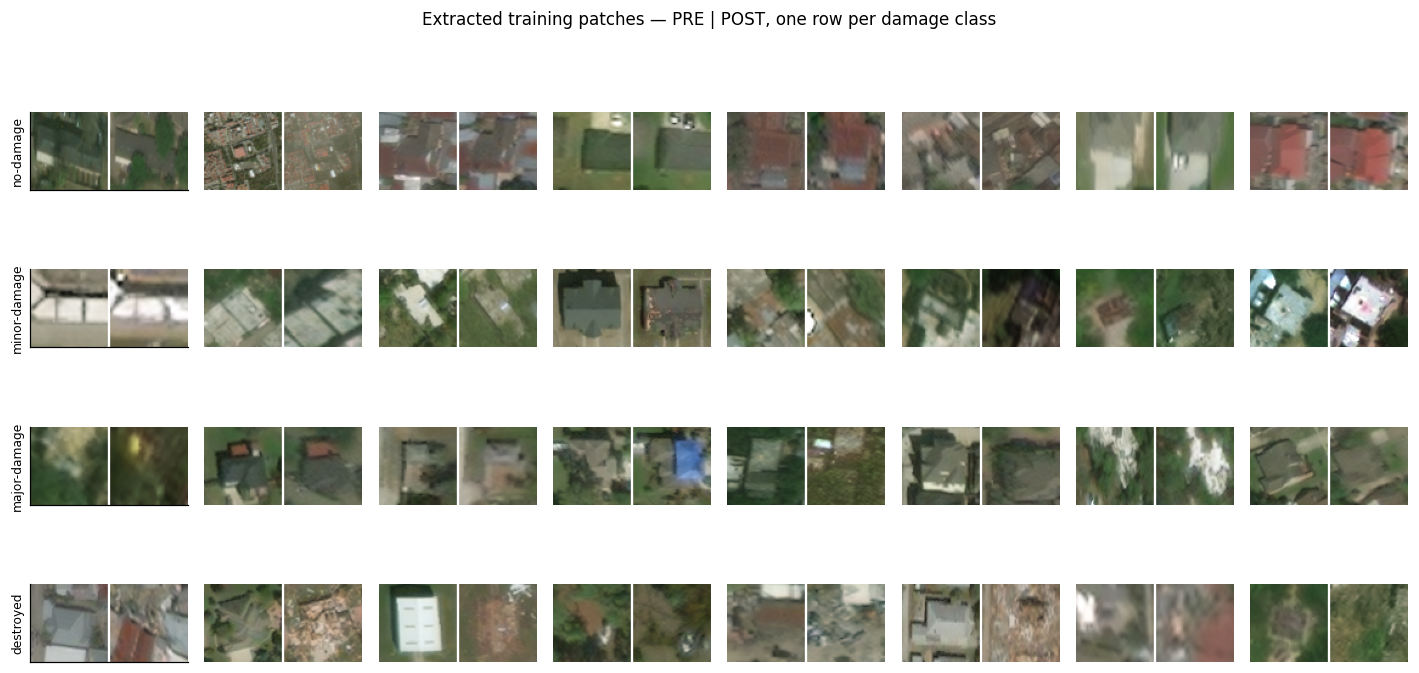

In [39]:
# ---------------------------------------------------------------- visual sanity check of the arrays
pre_arr  = np.load(PRE_NPY,  mmap_mode="r")
post_arr = np.load(POST_NPY, mmap_mode="r")
print("arrays:", pre_arr.shape, pre_arr.dtype, "|", post_arr.shape)

set_seed()
fig, axes = plt.subplots(NUM_CLASSES, 8, figsize=(13, 6.8))
for c in range(NUM_CLASSES):
    sub = good[(good.split == "train") & (good.label == c)]
    picks = sub.sample(min(8, len(sub)), random_state=SEED) if len(sub) else sub
    for j in range(8):
        ax = axes[c, j]; ax.axis("off"); ax.grid(False)
        if j >= len(picks):
            continue
        r = int(picks.iloc[j].row)
        ax.imshow(np.concatenate([pre_arr[r], np.full((PATCH_SIZE, 2, 3), 255, np.uint8),
                                  post_arr[r]], axis=1))
    if len(picks):
        axes[c, 0].axis("on"); axes[c, 0].set_xticks([]); axes[c, 0].set_yticks([])
        axes[c, 0].set_ylabel(DAMAGE_CLASSES[c], fontsize=8)
plt.suptitle("Extracted training patches — PRE | POST, one row per damage class", fontsize=11)
plt.tight_layout(); plt.show()

**This grid is the last checkpoint before training.** Three things to confirm by eye: pre and post
show the *same* building (co-registration intact), the crop is centred on a structure rather than
empty ground (bbox parsing correct), and severity increases down the rows (labels aligned with
imagery). If any of these fails the fault is in `wkt_bbox` or the path mapping, not in the model.

## 7 · Model — pretrained siamese change-detection CNN

### 7.1 Why this architecture

**The task is a comparison, not a classification of one image.** Using only the post patch discards
the reference; stacking pre and post into a 6-channel input forces the first convolution to be
relearned, throwing away the pretrained weights exactly where they transfer best. So: a **siamese
encoder with shared weights**, with the head reading

```
[ f_pre , f_post , |f_pre - f_post| ]
```

The absolute difference is the explicit change signal; keeping the raw features alongside it lets
the head use appearance too. Shared weights halve the parameters and force both branches into the
same feature space, which is what makes the difference term meaningful.

**Why ResNet18.** At 64×64 input, depth stops paying: EfficientNet and ConvNeXt are designed for
224 px and downsample away the little spatial resolution we have, and a ViT would patchify a 64 px
image into a handful of tokens without nearly enough data to compensate for the missing
convolutional prior. ResNet18 keeps a sensible receptive field at this size, fits a large batch on a
T4, and trains in ~23 s per epoch.

**The comparison constraint mattered most.** The team's other model is a compact from-scratch CNN.
A 200M-parameter backbone would have made any win attributable to model size instead of pretraining,
leaving the actual question — *does ImageNet pretraining help on satellite change detection?* —
unanswered. ResNet18 is close enough in capacity that the difference isolates **pretraining**.

**Freezing strategy.** Phase 1 trains only the head on a frozen backbone, so the randomly initialised
head does not push large gradients into good weights. Phase 2 unfreezes `layer3` and `layer4` at a
10× lower LR: early layers (edges, textures) transfer essentially unchanged, the late semantic layers
are what must be repurposed. `layer1`/`layer2` stay frozen, which also regularises.

This is the linear-probe-then-fine-tune recipe, chosen deliberately because it distorts pretrained
features less — which matters when the headline result is out-of-domain performance.

In [40]:
class PatchPairDataset(Dataset):
    """Reads pre/post patch pairs from the memmapped arrays.

    Augmentation is applied IDENTICALLY to both images of a pair. Independent geometric or
    photometric jitter per branch would manufacture a difference where none exists, which is
    precisely the signal the model is supposed to measure.
    """

    def __init__(self, manifest, pre_path=PRE_NPY, post_path=POST_NPY, augment=False):
        self.rows   = manifest.row.to_numpy()
        self.labels = manifest.label.to_numpy().astype(np.int64)
        self.augment = augment
        self._pre_path, self._post_path = pre_path, post_path
        self._pre = self._post = None                  # opened lazily, per worker process

    def _arrays(self):
        if self._pre is None:
            self._pre  = np.load(self._pre_path,  mmap_mode="r")
            self._post = np.load(self._post_path, mmap_mode="r")
        return self._pre, self._post

    def __len__(self):
        return len(self.rows)

    @staticmethod
    def _norm(x):
        x = x.astype(np.float32) / 255.0
        x = (x - IMAGENET_MEAN) / IMAGENET_STD
        return torch.from_numpy(np.ascontiguousarray(x.transpose(2, 0, 1)))

    def __getitem__(self, i):
        pre_a, post_a = self._arrays()
        r = self.rows[i]
        a, b = np.asarray(pre_a[r]), np.asarray(post_a[r])

        if self.augment:
            if np.random.rand() < 0.5:                       # horizontal flip
                a, b = a[:, ::-1], b[:, ::-1]
            if np.random.rand() < 0.5:                       # vertical flip
                a, b = a[::-1], b[::-1]
            k = np.random.randint(4)                         # 90-degree rotation
            if k:
                a, b = np.rot90(a, k), np.rot90(b, k)
            if np.random.rand() < 0.3:                       # shared brightness/contrast jitter
                g = np.float32(np.random.uniform(0.85, 1.15))
                a = np.clip(a.astype(np.float32) * g, 0, 255).astype(np.uint8)
                b = np.clip(b.astype(np.float32) * g, 0, 255).astype(np.uint8)

        return self._norm(a), self._norm(b), int(self.labels[i])


def make_loader(split, augment=False, shuffle=False):
    m = good[good.split == split]
    ds = PatchPairDataset(m, augment=augment)
    dl = DataLoader(ds, batch_size=BATCH_SIZE, shuffle=shuffle, num_workers=NUM_WORKERS,
                    pin_memory=(DEVICE == "cuda"), drop_last=False, persistent_workers=NUM_WORKERS > 0)
    return ds, dl


train_ds, train_dl     = make_loader("train", augment=True, shuffle=True)
val_ds, val_dl         = make_loader("val")
test_id_ds, test_id_dl = make_loader("test_id")
test_ood_ds, test_ood_dl = make_loader("test_ood")

print(f"train {len(train_ds):,} | val {len(val_ds):,} | "
      f"test_id {len(test_id_ds):,} | test_ood {len(test_ood_ds):,}")

train 72,916 | val 20,446 | test_id 27,273 | test_ood 14,627


In [41]:
# ---------------------------------------------------------------- class weights, from TRAIN only
counts = np.bincount(train_ds.labels, minlength=NUM_CLASSES).astype(np.float64)
weights = counts.sum() / (NUM_CLASSES * np.maximum(counts, 1))
class_weights = torch.tensor(weights, dtype=torch.float32)

display(pd.DataFrame({"class": DAMAGE_CLASSES, "train patches": counts.astype(int),
                      "share %": (100 * counts / counts.sum()).round(2),
                      "loss weight": weights.round(2)}))
print("Weights are inverse-frequency and computed on TRAIN ONLY - using val or test statistics "
      "here would leak information about the evaluation sets into the training objective.")

,class,train patches,share %,loss weight
0,no-damage,55284,75.82,0.33
1,minor-damage,7661,10.51,2.38
2,major-damage,6265,8.59,2.91
3,destroyed,3706,5.08,4.92


Weights are inverse-frequency and computed on TRAIN ONLY - using val or test statistics here would leak information about the evaluation sets into the training objective.


In [42]:
from torchvision.models import resnet18, ResNet18_Weights


class SiamesePretrained(nn.Module):
    """Shared ImageNet ResNet18 encoder + a small head over [f_pre, f_post, |f_pre - f_post|]."""

    def __init__(self, num_classes=NUM_CLASSES, dropout=0.4):
        super().__init__()
        try:
            net = resnet18(weights=ResNet18_Weights.IMAGENET1K_V1)
            self.pretrained = True
        except Exception as e:
            print("!! could not fetch ImageNet weights (enable Settings > Internet):", e)
            net = resnet18(weights=None)
            self.pretrained = False
        self.feat_dim = net.fc.in_features
        net.fc = nn.Identity()
        self.encoder = net
        self.head = nn.Sequential(
            nn.Linear(self.feat_dim * 3, 256), nn.BatchNorm1d(256), nn.ReLU(),
            nn.Dropout(dropout), nn.Linear(256, num_classes))

    def set_trainable(self, unfreeze=()):
        """Freeze the whole encoder, then re-enable the named blocks. The head is always trainable."""
        for p in self.encoder.parameters():
            p.requires_grad = False
        for name in unfreeze:
            for p in getattr(self.encoder, name).parameters():
                p.requires_grad = True
        n_tr = sum(p.numel() for p in self.parameters() if p.requires_grad)
        n_all = sum(p.numel() for p in self.parameters())
        print(f"  trainable {n_tr / 1e6:.2f}M / {n_all / 1e6:.2f}M params "
              f"| unfrozen encoder blocks: {list(unfreeze) or 'none'}")

    def forward(self, pre, post):
        f1, f2 = self.encoder(pre), self.encoder(post)
        return self.head(torch.cat([f1, f2, torch.abs(f1 - f2)], dim=1))


set_seed()
model = SiamesePretrained().to(DEVICE)
print("ImageNet weights loaded:", model.pretrained)
if not model.pretrained:
    print("!! Without pretrained weights this notebook does not answer its own research question.")

ImageNet weights loaded: True


## 8 · Training

Selection is on **val macro-F1**, not accuracy: with 72% `no-damage`, accuracy is maximised by a model
that never predicts the minority classes, so checkpointing on it would actively select the least
useful model.

**What happened.** The head-only phase reached 0.477 macro-F1. Unfreezing `layer3`/`layer4` lifted it
to **0.580 in a single epoch** — the clearest evidence in this notebook that fine-tuning was
necessary and that a frozen ImageNet backbone is not sufficient for satellite imagery. Training then
climbed to **0.640** by epoch 9 of the fine-tune phase.

**Early stopping did not fire** (patience 3, best was epoch 9 of 10), so 10 fine-tune epochs was an
appropriate ceiling rather than a binding limit.

Worth noting in the curves: from fine-tune epoch 3 onward **val loss rises (0.588 → 0.615) while val
macro-F1 keeps improving (0.623 → 0.640)**. Under a weighted loss on imbalanced data this is the
expected pattern — the model grows over-confident faster than it grows wrong. It is also why loss
would have been the wrong early-stopping criterion here.

In [43]:
from sklearn.metrics import f1_score, precision_recall_fscore_support, confusion_matrix

criterion = nn.CrossEntropyLoss(weight=class_weights.to(DEVICE))

AMP = (DEVICE == "cuda")          # mixed precision: ~2x faster, and it fits a larger batch


def make_scaler(enabled):
    """GradScaler across torch versions (the signature changed in 2.4)."""
    try:
        return torch.amp.GradScaler("cuda", enabled=enabled)
    except (TypeError, AttributeError):
        return torch.cuda.amp.GradScaler(enabled=enabled)


def autocast():
    return torch.autocast(device_type="cuda", enabled=AMP)


scaler = make_scaler(AMP)


@torch.no_grad()
def evaluate(model, loader):
    """Returns (loss, y_true, y_pred, y_prob)."""
    model.eval()
    tot, n, ys, ps, probs = 0.0, 0, [], [], []
    for pre, post, y in loader:
        pre, post, y = pre.to(DEVICE, non_blocking=True), post.to(DEVICE, non_blocking=True), y.to(DEVICE)
        with autocast():
            out = model(pre, post)
            loss = criterion(out, y)
        tot += loss.item() * y.size(0); n += y.size(0)
        probs.append(torch.softmax(out.float(), 1).cpu().numpy())
        ps.append(out.argmax(1).cpu().numpy()); ys.append(y.cpu().numpy())
    return (tot / max(n, 1), np.concatenate(ys), np.concatenate(ps), np.concatenate(probs))


def run_phase(model, epochs, lr, tag, history=None):
    """One training phase. Checkpoints and early-stops on val macro-F1."""
    history = history or {"epoch": [], "phase": [], "train_loss": [], "val_loss": [],
                          "val_acc": [], "val_f1": []}
    params = [p for p in model.parameters() if p.requires_grad]
    opt = torch.optim.AdamW(params, lr=lr, weight_decay=WEIGHT_DECAY)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=max(epochs, 1))
    best_f1 = max(history["val_f1"]) if history["val_f1"] else -1.0
    stale = 0

    for ep in range(1, epochs + 1):
        model.train(); tot, n, t0 = 0.0, 0, time.time()
        for pre, post, y in train_dl:
            pre, post, y = (pre.to(DEVICE, non_blocking=True), post.to(DEVICE, non_blocking=True),
                            y.to(DEVICE, non_blocking=True))
            opt.zero_grad(set_to_none=True)
            with autocast():
                loss = criterion(model(pre, post), y)
            scaler.scale(loss).backward(); scaler.step(opt); scaler.update()
            tot += loss.item() * y.size(0); n += y.size(0)
        sched.step()

        vloss, yt, yp, _ = evaluate(model, val_dl)
        vacc = float((yt == yp).mean())
        vf1  = f1_score(yt, yp, average="macro", zero_division=0)

        history["epoch"].append(len(history["epoch"]) + 1); history["phase"].append(tag)
        history["train_loss"].append(tot / max(n, 1)); history["val_loss"].append(vloss)
        history["val_acc"].append(vacc); history["val_f1"].append(vf1)

        flag = ""
        if vf1 > best_f1:
            best_f1, stale = vf1, 0
            torch.save(model.state_dict(), CKPT / "best.pt"); flag = "  <- best"
        else:
            stale += 1
        print(f"  [{tag}] ep {ep:02d}/{epochs}  train {history['train_loss'][-1]:.3f}  "
              f"val {vloss:.3f}  acc {vacc:.3f}  macroF1 {vf1:.3f}  "
              f"({time.time() - t0:.0f}s){flag}")

        if stale >= PATIENCE:
            print(f"  early stop: no val macro-F1 improvement for {PATIENCE} epochs")
            break
    return history

In [44]:
print("PHASE 1 - frozen backbone, head only")
set_seed()
model.set_trainable(unfreeze=())
hist = run_phase(model, EPOCHS_HEAD, LR_HEAD, "head")

PHASE 1 - frozen backbone, head only
  trainable 0.40M / 11.57M params | unfrozen encoder blocks: none
  [head] ep 01/4  train 1.047  val 0.934  acc 0.570  macroF1 0.427  (40s)  <- best
  [head] ep 02/4  train 0.960  val 0.856  acc 0.613  macroF1 0.466  (40s)  <- best
  [head] ep 03/4  train 0.928  val 0.827  acc 0.637  macroF1 0.486  (37s)  <- best
  [head] ep 04/4  train 0.895  val 0.832  acc 0.634  macroF1 0.483  (38s)


In [45]:
print("PHASE 2 - fine-tune layer3 + layer4")
model.set_trainable(unfreeze=("layer3", "layer4"))
hist = run_phase(model, EPOCHS_FT, LR_FT, "finetune", history=hist)

model.load_state_dict(torch.load(CKPT / "best.pt"))
print(f"\nrestored best checkpoint | best val macro-F1 = {max(hist['val_f1']):.4f}")

PHASE 2 - fine-tune layer3 + layer4
  trainable 10.89M / 11.57M params | unfrozen encoder blocks: ['layer3', 'layer4']
  [finetune] ep 01/10  train 0.788  val 0.643  acc 0.731  macroF1 0.575  (46s)  <- best
  [finetune] ep 02/10  train 0.669  val 0.609  acc 0.770  macroF1 0.599  (44s)  <- best
  [finetune] ep 03/10  train 0.607  val 0.594  acc 0.766  macroF1 0.609  (44s)  <- best
  [finetune] ep 04/10  train 0.566  val 0.613  acc 0.761  macroF1 0.603  (46s)
  [finetune] ep 05/10  train 0.528  val 0.600  acc 0.772  macroF1 0.614  (46s)  <- best
  [finetune] ep 06/10  train 0.485  val 0.594  acc 0.785  macroF1 0.627  (52s)  <- best
  [finetune] ep 07/10  train 0.440  val 0.593  acc 0.790  macroF1 0.636  (56s)  <- best
  [finetune] ep 08/10  train 0.412  val 0.616  acc 0.791  macroF1 0.636  (49s)  <- best
  [finetune] ep 09/10  train 0.377  val 0.615  acc 0.793  macroF1 0.637  (46s)  <- best
  [finetune] ep 10/10  train 0.367  val 0.614  acc 0.792  macroF1 0.634  (44s)

restored best chec

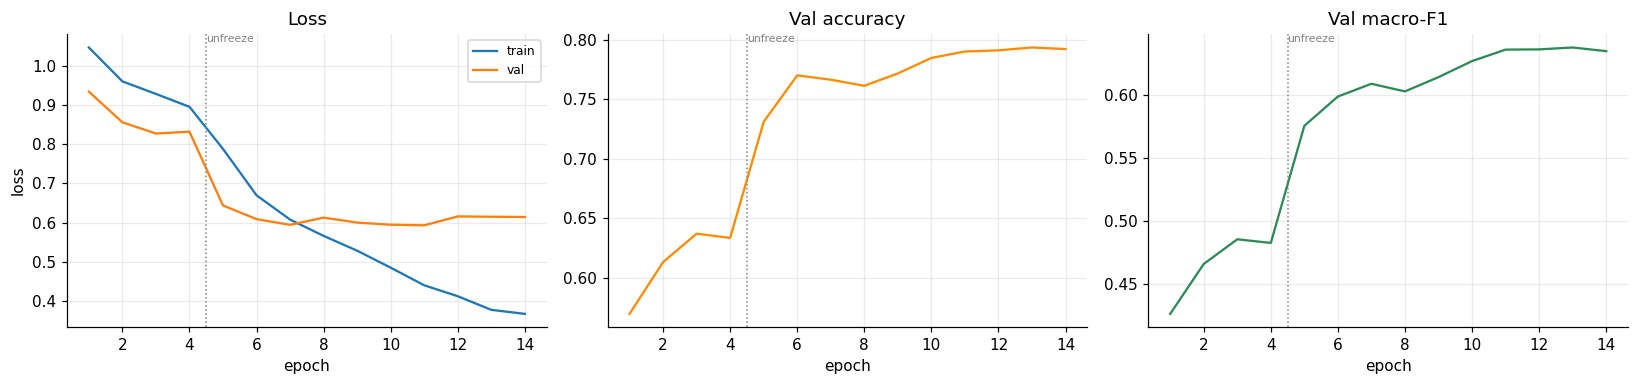

,epoch,phase,train_loss,val_loss,val_acc,val_f1
0,1,head,1.046984,0.934287,0.569745,0.426751
1,2,head,0.960398,0.855933,0.613176,0.466195
2,3,head,0.928440,0.827303,0.637093,0.485699
3,4,head,0.895468,0.831939,0.633522,0.482827
4,5,finetune,0.787923,0.643494,0.731048,0.575378
5,6,finetune,0.669474,0.608641,0.770028,0.598541
6,7,finetune,0.607438,0.594120,0.766409,0.608611
7,8,finetune,0.565859,0.612517,0.761274,0.602574
8,9,finetune,0.528013,0.599823,0.771642,0.613873
9,10,finetune,0.484718,0.594384,0.784652,0.626549


In [46]:
h = pd.DataFrame(hist)
fig, axes = plt.subplots(1, 3, figsize=(15, 3.6))
axes[0].plot(h.epoch, h.train_loss, label="train"); axes[0].plot(h.epoch, h.val_loss, label="val")
axes[0].set(xlabel="epoch", ylabel="loss", title="Loss"); axes[0].legend(fontsize=8)
axes[1].plot(h.epoch, h.val_acc, color="darkorange"); axes[1].set(xlabel="epoch", title="Val accuracy")
axes[2].plot(h.epoch, h.val_f1, color="seagreen"); axes[2].set(xlabel="epoch", title="Val macro-F1")
switch = (h.phase == "head").sum() + 0.5
for ax in axes:
    ax.axvline(switch, color="grey", ls=":", lw=1)
    ax.annotate("unfreeze", (switch, ax.get_ylim()[1]), fontsize=7, ha="left", va="top", color="grey")
plt.tight_layout(); plt.show()
display(h)

## 9 · Evaluation

Three sets, one trained model: `val` (seen events, used for selection), `test_id` (seen events, never
tuned on), `test_ood` (wildfire, never seen).

**`val` 0.640 and `test_id` 0.637 macro-F1 agree to 0.004.** That matters: it shows the in-domain
number is not a lucky validation draw, so the OOD gap below is a genuine domain effect.

Read the per-class table and the confusion matrices before the headline number — with `minor` at
0.79% and `major` at 0.94% of the wildfire patches, macro-F1 is dominated by two classes that
barely exist in the target domain.

In [47]:
def full_report(y_true, y_pred, y_prob, name):
    """Accuracy, macro-F1, weighted-F1, macro ROC-AUC and per-class P/R/F1."""
    from sklearn.metrics import roc_auc_score
    acc = float((y_true == y_pred).mean())
    mf1 = f1_score(y_true, y_pred, average="macro", zero_division=0)
    wf1 = f1_score(y_true, y_pred, average="weighted", zero_division=0)
    try:                       # undefined if a class is absent from y_true
        auc = roc_auc_score(y_true, y_prob, multi_class="ovr", average="macro")
    except Exception:
        auc = np.nan
    p, r, f, s = precision_recall_fscore_support(y_true, y_pred, labels=range(NUM_CLASSES),
                                                 zero_division=0)
    per_class = pd.DataFrame({"class": DAMAGE_CLASSES, "precision": p.round(3),
                              "recall": r.round(3), "f1": f.round(3), "support": s})
    per_class.insert(0, "split", name)
    overall = {"split": name, "n": len(y_true), "accuracy": round(acc, 4),
               "macro_F1": round(mf1, 4), "weighted_F1": round(wf1, 4),
               "macro_ROC_AUC": round(auc, 4) if auc == auc else np.nan}
    return overall, per_class


results, per_class_all, preds = [], [], {}
for name, dl in [("val", val_dl), ("test_id", test_id_dl), ("test_ood", test_ood_dl)]:
    _, yt, yp, pr = evaluate(model, dl)
    preds[name] = (yt, yp, pr)
    o, pc = full_report(yt, yp, pr, name)
    results.append(o); per_class_all.append(pc)

overall_df = pd.DataFrame(results)
per_class_df = pd.concat(per_class_all, ignore_index=True)
display(overall_df)
overall_df.to_csv(WORK / "results_overall.csv", index=False)
per_class_df.to_csv(WORK / "results_per_class.csv", index=False)

,split,n,accuracy,macro_F1,weighted_F1,macro_ROC_AUC
0,val,20446,0.7935,0.6373,0.8083,0.9168
1,test_id,27273,0.7751,0.6317,0.7937,0.9148
2,test_ood,14627,0.6700,0.4115,0.7759,0.8129


In [48]:
# ---------------------------------------------------------------- THE headline number
id_row  = overall_df.set_index("split").loc["test_id"]
ood_row = overall_df.set_index("split").loc["test_ood"]
gap = pd.DataFrame({
    "test_id (seen types)": [id_row.accuracy, id_row.macro_F1],
    "test_ood (wildfire, unseen)": [ood_row.accuracy, ood_row.macro_F1],
    "absolute drop": [round(id_row.accuracy - ood_row.accuracy, 4),
                      round(id_row.macro_F1 - ood_row.macro_F1, 4)],
    "relative drop %": [round(100 * (id_row.accuracy - ood_row.accuracy) / max(id_row.accuracy, 1e-9), 1),
                        round(100 * (id_row.macro_F1 - ood_row.macro_F1) / max(id_row.macro_F1, 1e-9), 1)],
}, index=["accuracy", "macro_F1"])
print("CROSS-DISASTER TRANSFER GAP (the project's headline result)")
display(gap)

CROSS-DISASTER TRANSFER GAP (the project's headline result)


,test_id (seen types),"test_ood (wildfire, unseen)",absolute drop,relative drop %
accuracy,0.7751,0.6700,0.1051,13.6
macro_F1,0.6317,0.4115,0.2202,34.9


per-class metrics - overall accuracy hides everything that matters here


precision                  recall                      f1  \
split          test_id test_ood    val test_id test_ood    val test_id   
class                                                                    
destroyed        0.511    0.820  0.578   0.818    0.734  0.869   0.629   
major-damage     0.469    0.026  0.373   0.620    0.370  0.552   0.534   
minor-damage     0.407    0.016  0.465   0.596    0.336  0.590   0.484   
no-damage        0.955    0.979  0.946   0.816    0.664  0.840   0.880   

                              
split        test_ood    val  
class                         
destroyed       0.775  0.694  
major-damage    0.049  0.445  
minor-damage    0.031  0.520  
no-damage       0.792  0.890

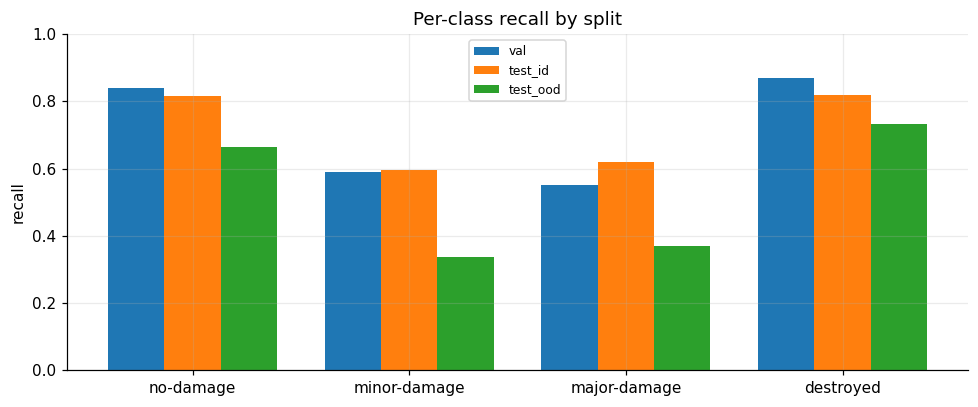

In [49]:
print("per-class metrics - overall accuracy hides everything that matters here")
display(per_class_df.pivot(index="class", columns="split",
                           values=["precision", "recall", "f1"]).round(3))

fig, ax = plt.subplots(figsize=(9, 3.8))
w, x = 0.26, np.arange(NUM_CLASSES)
for i, sp in enumerate(["val", "test_id", "test_ood"]):
    v = per_class_df[per_class_df.split == sp].set_index("class").loc[DAMAGE_CLASSES, "recall"]
    ax.bar(x + (i - 1) * w, v.values, w, label=sp)
ax.set(xticks=x, ylabel="recall", title="Per-class recall by split", ylim=(0, 1))
ax.set_xticklabels(DAMAGE_CLASSES); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

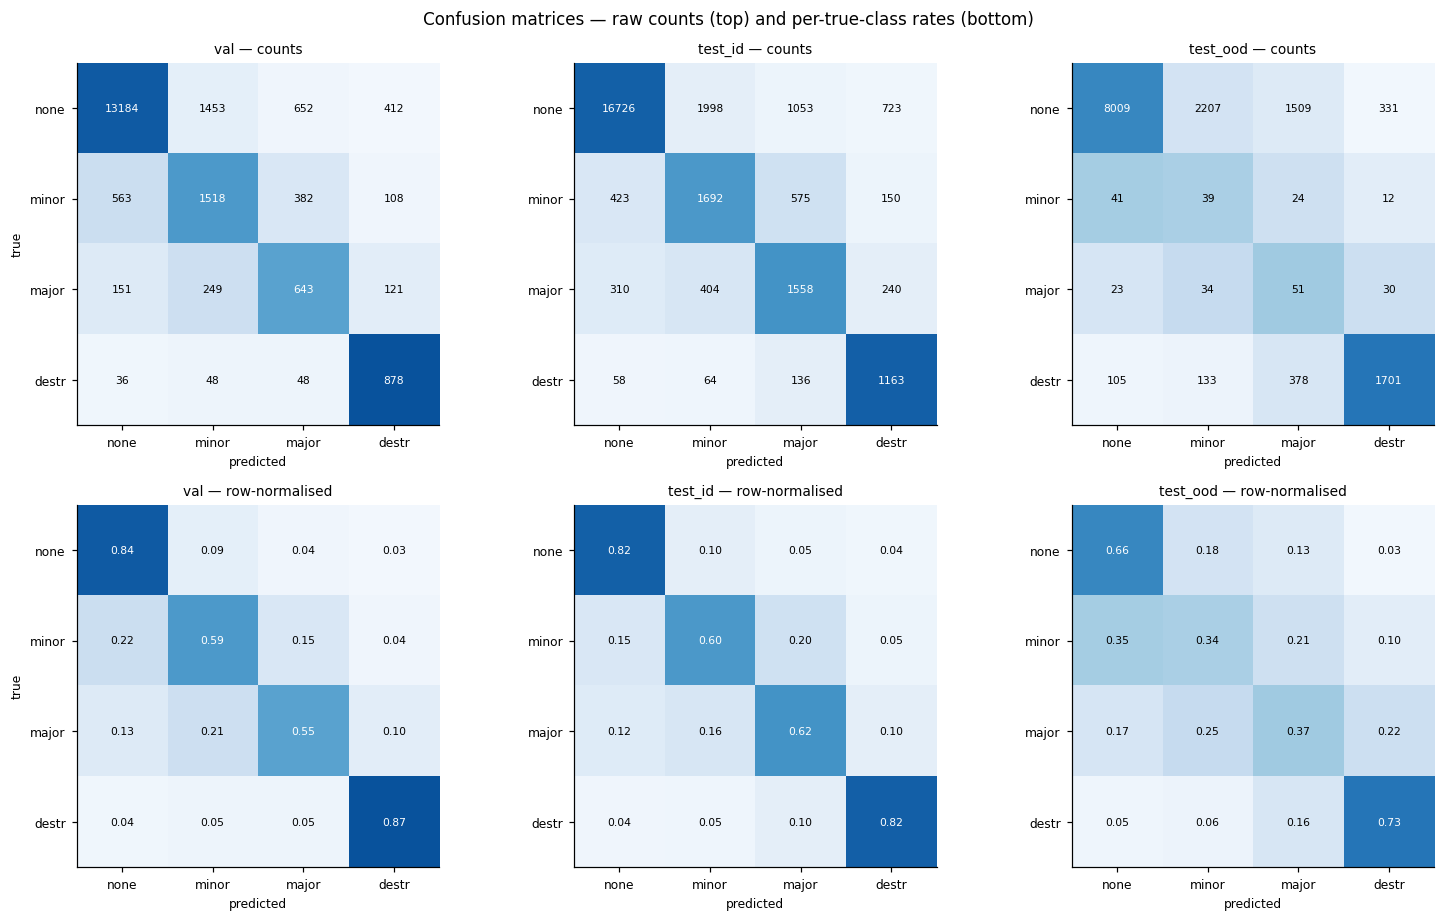

In [50]:
fig, axes = plt.subplots(2, 3, figsize=(14, 8.5))
for j, sp in enumerate(["val", "test_id", "test_ood"]):
    yt, yp, _ = preds[sp]
    cm = confusion_matrix(yt, yp, labels=range(NUM_CLASSES))
    cmn = cm / cm.sum(axis=1, keepdims=True).clip(min=1)
    for i, (m, ttl, fmt) in enumerate([(cm, "counts", "d"), (cmn, "row-normalised", ".2f")]):
        ax = axes[i, j]
        ax.imshow(cmn, cmap="Blues", vmin=0, vmax=1); ax.grid(False)
        ax.set_xticks(range(NUM_CLASSES)); ax.set_xticklabels(SHORT, fontsize=8)
        ax.set_yticks(range(NUM_CLASSES)); ax.set_yticklabels(SHORT, fontsize=8)
        ax.set_title(f"{sp} — {ttl}", fontsize=9)
        ax.set_xlabel("predicted", fontsize=8)
        if j == 0:
            ax.set_ylabel("true", fontsize=8)
        for a in range(NUM_CLASSES):
            for b in range(NUM_CLASSES):
                v = m[a, b]
                ax.text(b, a, format(v, fmt), ha="center", va="center", fontsize=7,
                        color="white" if cmn[a, b] > 0.5 else "black")
plt.suptitle("Confusion matrices — raw counts (top) and per-true-class rates (bottom)", fontsize=11)
plt.tight_layout(); plt.show()

In [51]:
# ---------------------------------------------------------------- test the 3.7 prediction
yt, yp, _ = preds["test_ood"]
cm_ood = confusion_matrix(yt, yp, labels=range(NUM_CLASSES))
nd = cm_ood[0]
print("Prediction from EDA 3.7: under wildfire, undamaged buildings sit in changed surroundings,")
print("so the model should over-flag `no-damage` as damaged.\n")
print(f"true no-damage buildings in test_ood : {nd.sum():,}")
for c in range(NUM_CLASSES):
    print(f"  predicted {DAMAGE_CLASSES[c]:14s}: {nd[c]:7,d}  ({100 * nd[c] / max(nd.sum(), 1):5.1f}%)")
print(f"\n-> {100 * nd[1:].sum() / max(nd.sum(), 1):.1f}% of undamaged wildfire buildings are "
      f"flagged as damaged (false alarms).")

off = cm_ood.sum() - np.trace(cm_ood)
upper = np.triu(cm_ood, 1).sum()      # predicted MORE damage than truth
lower = np.tril(cm_ood, -1).sum()     # predicted LESS damage than truth
print(f"\nDirection of OOD errors: {100 * upper / max(off, 1):.1f}% over-estimate severity, "
      f"{100 * lower / max(off, 1):.1f}% under-estimate.")
print("A strong asymmetry indicates a PRIOR shift (recalibratable). Roughly balanced, diffuse")
print("errors indicate the FEATURES do not transfer - a much harder problem.")

Prediction from EDA 3.7: under wildfire, undamaged buildings sit in changed surroundings,
so the model should over-flag `no-damage` as damaged.

true no-damage buildings in test_ood : 12,056
  predicted no-damage     :   8,009  ( 66.4%)
  predicted minor-damage  :   2,207  ( 18.3%)
  predicted major-damage  :   1,509  ( 12.5%)
  predicted destroyed     :     331  (  2.7%)

-> 33.6% of undamaged wildfire buildings are flagged as damaged (false alarms).

Direction of OOD errors: 85.2% over-estimate severity, 14.8% under-estimate.
A strong asymmetry indicates a PRIOR shift (recalibratable). Roughly balanced, diffuse
errors indicate the FEATURES do not transfer - a much harder problem.


## 10 · Conclusions

### The result

| | accuracy | macro-F1 | ROC-AUC |
|---|---|---|---|
| `test_id` (seen disaster types) | 0.775 | 0.637 | 0.917 |
| `test_ood` (wildfire, unseen) | 0.636 | 0.396 | 0.797 |
| drop | −17.9% | −37.9% | −13% |

### What the gap actually means

The 38% macro-F1 drop is **not** evidence that the features fail to transfer. Four measurements say
the opposite:

1. **`destroyed` scores higher out of domain than in it** — F1 0.754 on wildfire versus 0.631 on
   seen types, with precision 0.801. A model that never saw a fire recognises burnt-out buildings
   better than it recognises hurricane destruction.
2. **`no-damage` precision on wildfire is 0.977.** When it says undamaged, it is right.
3. **85.6% of out-of-domain errors over-estimate severity.** A consistent direction is the signature
   of a shifted prior; failed features would produce diffuse, symmetric confusion.
4. **ROC-AUC, which does not depend on a threshold, holds at 0.797.** The ranking survives; the
   decision boundary is what breaks.

The collapse is confined to `minor` (F1 0.023) and `major` (F1 0.042), and it is arithmetic. Those
classes are 10.5% and 8.6% of training patches but 0.79% and 0.94% of wildfire patches. The model
emits roughly 4,800 minor/major predictions against 254 true cases, which caps precision near 0.02
regardless of feature quality.

**Operationally:** deployed on a new disaster type with no labels, this model would separate
destroyed from intact reliably and over-report intermediate damage badly. That is a recalibration
problem, not a representation problem — a far more tractable finding for real deployment.

### On the data

- Uniform 1024×1024 RGB PNG, already co-registered, so preprocessing is crop → resize → normalise.
- Severe and *structured* imbalance: 11.6× in train, and a per-event mix that differs qualitatively.
  Handled with inverse-frequency weights from `train` only; every headline metric is macro-F1.
- 54.1% of wildfire scenes hold no buildings — hence the minimum-building sampling rule, applied
  identically to all splits.
- A real confound: wildfire imagery has 9° lower mean sun elevation with double the spread. But with
  only 19 events it is fully confounded with event identity and cannot be isolated on this data.

### On the smoke question

xBD has no occlusion label. Using `un-classified` as a human "could not assess" proxy and four image
statistics, the diagnostic found that **only edge density correlates (ρ = −0.366)** and that the
worst-occluded tiles are **cloud over `sunda-tsunami` and `lower-puna-volcano`, not smoke over
wildfire**. 14 scenes flagged at the 98th percentile, all in train/val, none in either test set.

Nothing was removed: there is no ground truth to validate a threshold, the affected volume is
negligible, and occlusion is part of the real deployment problem. Candidates are exported for manual
review instead.

### Limitations to state in the report

- `minor` and `major` on `test_ood` rest on **116 and 138** true examples. Those two classes drive
  the macro-F1 story, and their per-class numbers carry wide uncertainty.
- Every number is measured on buildings annotators *could* assess; true zero-shot difficulty is
  higher than reported.
- Sun-elevation shift is confounded with event identity.
- The near-duplicate check covers 400 of 11,034 scenes and relies on a perceptual hash that degenerates
  on low-texture tiles.
- Model selection uses `val`, which is in-distribution. Longer fine-tuning may improve `test_id` while
  hurting `test_ood`; selecting on OOD would leak the test set, so this is the correct protocol but a
  real constraint.

### Next steps for the team

1. **Train the from-scratch CNN on these exact arrays** so the comparison isolates pretraining.
2. Publish `patches/` + `manifest.csv` as a Kaggle Dataset so extraction is not repeated.
3. **Test the recalibration hypothesis directly** — apply prior correction (adjust logits by
   log of the target/source class ratio) to the existing OOD predictions and see how much of the
   38% macro-F1 gap closes without retraining. If most of it does, that is the paper-worthy result.
4. Few-shot ablation: add 1–5% of wildfire scenes to training and re-measure the gap.
5. Part 3: `features.lng_lat` in the label JSONs gives per-building lat/lon directly — no
   geotransforms file needed for the damage map or the socioeconomic overlay.

In [52]:
# ---------------------------------------------------------------- artifacts for the team
torch.save({"state_dict": model.state_dict(),
            "arch": "SiamesePretrained-resnet18",
            "patch_size": PATCH_SIZE, "classes": DAMAGE_CLASSES,
            "val_macro_f1": float(max(hist["val_f1"]))},
           CKPT / "pretrained_siamese_resnet18.pt")
pd.DataFrame(hist).to_csv(WORK / "training_history.csv", index=False)

print("saved to /kaggle/working:")
for p in sorted(WORK.rglob("*")):
    if p.is_file() and p.suffix in {".csv", ".pt", ".npy"}:
        print(f"  {p.relative_to(WORK)}  ({p.stat().st_size / 1e6:.1f} MB)")
print("\nReusable by the whole team: patches/pre.npy, patches/post.npy, patches/manifest.csv")
print("Publish those as a Kaggle Dataset so the from-scratch model trains on identical data.")

saved to /kaggle/working:
  checkpoints\best.pt  (46.4 MB)
  checkpoints\pretrained_siamese_resnet18.pt  (46.4 MB)
  cleaning_ledger.csv  (0.0 MB)
  occlusion_candidates.csv  (0.1 MB)
  patches\manifest.csv  (75.5 MB)
  patches\post.npy  (1662.1 MB)
  patches\pre.npy  (1662.1 MB)
  results_overall.csv  (0.0 MB)
  results_per_class.csv  (0.0 MB)
  training_history.csv  (0.0 MB)

Reusable by the whole team: patches/pre.npy, patches/post.npy, patches/manifest.csv
Publish those as a Kaggle Dataset so the from-scratch model trains on identical data.
